# Clasificación de movimientos artísticos con PySpark y MLlib

Nombre: Mauricio Olguín Sánchez

Matrícula: A01711522

## Contexto

En esta evidencia construyo con PySpark un flujo completo (ETL, EDA, modelo, evaluación y predicción) para clasificar una pintura en su movimiento artístico, a partir de rasgos de color, textura y forma de la imagen.

Utilizo el dataset [Best Artworks of All Time](https://www.kaggle.com/datasets/ikarus777/best-artworks-of-all-time) de Kaggle, que incluye 8,774 archivos JPG (1.6 GB) de 50 artistas y `artists.csv`, con la biografía, el género y la nacionalidad de cada artista. Todo el manejo de datos lo hago con Spark y sólo utilizo matplotlib para dibujar resultados ya agregados.

Los pasos que seguí son los siguientes:

1. Preparación del ambiente
2. ETL: extracción, transformación y carga
3. Análisis exploratorio (EDA)
4. Modelo de clasificación con MLlib
5. Evaluación
6. Predicciones
7. Exportación para el tablero
8. Tablero en Tableau Public
9. Conclusiones

## 1. Preparación del ambiente

Primero, preparo el ambiente. La notebook corre en local con Python 3.12, `pyspark` 4.2, `numpy`, `Pillow` y `matplotlib`, y Spark necesita Java 17. Si se quiere correr en Google Colab, basta con descomentar la siguiente celda, la cual instala PySpark y descarga el dataset con la API de Kaggle.

In [1]:
# [Colab] Instalar PySpark y descargar el dataset (en local ya están en el venv y en data/)
# !pip install -q pyspark
# from google.colab import files
# files.upload()   # subir kaggle.json (Kaggle > Settings > Create New Token)
# !mkdir -p ~/.kaggle && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
# !kaggle datasets download -d ikarus777/best-artworks-of-all-time -p data/archive --unzip

Después, cargo las librerías, defino las rutas y creo la sesión de Spark en modo local. Le asigno 8 GB de memoria al driver y utilizo particiones de 64 MB para repartir las imágenes entre los núcleos.

In [2]:
import io
import os
import sys
import glob
import shutil

# Los workers de Spark deben usar el mismo Python que la notebook; si no, toman el del sistema
os.environ["PYSPARK_PYTHON"] = sys.executable

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageFilter

from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F
from pyspark.sql import types as T
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import StringIndexer, VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator
from pyspark.ml.stat import Correlation
from pyspark.ml.functions import vector_to_array

DATA_DIR = "data/archive"
IMAGES_DIR = f"{DATA_DIR}/images/images"   # imágenes originales; resized/ es una copia reducida y no se usa
NEW_DIR = "data/new_paintings"             # pinturas que no están en el dataset (sección 6)
OUTPUT_DIR = "outputs"
TABLEAU_DIR = "tableau"
SEED = 42

spark = (SparkSession.builder
         .appName("Movimientos artísticos - PySpark ML")
         .master("local[*]")
         .config("spark.driver.memory", "8g")
         .config("spark.sql.files.maxPartitionBytes", "64m")   # particiones chicas para repartir las imágenes entre núcleos
         .config("spark.sql.shuffle.partitions", "8")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

# Render nativo de PySpark: display(df) muestra los DataFrames como tabla HTML
spark.conf.set("spark.sql.repl.eagerEval.enabled", True)
spark.conf.set("spark.sql.repl.eagerEval.maxNumRows", 50)
spark.conf.set("spark.sql.repl.eagerEval.truncate", 0)

# Estilo común de las gráficas: rejilla tenue y sin bordes superiores ni derechos
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e1", "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "axes.edgecolor": "#a3a29c", "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e", "figure.dpi": 110})

print("Versión de Spark:", spark.version)
print("Núcleos disponibles:", spark.sparkContext.defaultParallelism)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/05 11:18:18 WARN Utils: Your hostname, MacBook-Pro-de-Mauricio-2.local, resolves to a loopback address: 127.0.0.1; using 10.25.94.103 instead (on interface en0)
26/11/05 11:18:18 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/05 11:18:19 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Versión de Spark: 4.2.0
Núcleos disponibles: 10


La sesión quedó lista con Spark 4.2.0 y 10 núcleos disponibles.

## 2. ETL: extracción, transformación y carga

### 2.1 Extracción

Para iniciar, leo las imágenes con la fuente `binaryFile`, que carga cada archivo como una fila con su ruta, su tamaño y su contenido. También leo `artists.csv`, con una fila por artista. Como la columna `bio` contiene comas y saltos de línea, lo leo con `multiLine`.

In [3]:
raw_images = (spark.read.format("binaryFile")
              .option("pathGlobFilter", "*.jpg")
              .option("recursiveFileLookup", "true")
              .load(IMAGES_DIR))

artists_raw = spark.read.csv(f"{DATA_DIR}/artists.csv", header=True, multiLine=True, escape='"', inferSchema=True)

volume = raw_images.agg(F.count("*").alias("files"), F.sum("length").alias("bytes")).first()
print(f"Imágenes: {volume['files']:,} archivos | {volume['bytes'] / 1024**3:.2f} GB | {raw_images.rdd.getNumPartitions()} particiones")
print(f"Artistas: {artists_raw.count()} filas | Columnas: {artists_raw.columns}")
raw_images.printSchema()
display(artists_raw.drop("bio", "wikipedia").limit(5))

Imágenes: 8,774 archivos | 1.56 GB | 558 particiones
Artistas: 50 filas | Columnas: ['id', 'name', 'years', 'genre', 'nationality', 'bio', 'wikipedia', 'paintings']
root
 |-- path: string (nullable = true)
 |-- modificationTime: timestamp (nullable = true)
 |-- length: long (nullable = true)
 |-- content: binary (nullable = true)



id,name,years,genre,nationality,paintings
0,Amedeo Modigliani,1884 - 1920,Expressionism,Italian,193
1,Vasiliy Kandinskiy,1866 - 1944,"Expressionism,Abstractionism",Russian,88
2,Diego Rivera,1886 - 1957,"Social Realism,Muralism",Mexican,70
3,Claude Monet,1840 - 1926,Impressionism,French,73
4,Rene Magritte,1898 - 1967,"Surrealism,Impressionism",Belgian,194


Spark leyó 8,774 archivos (1.56 GB) en 558 particiones, y `artists.csv` trae 50 filas, una por artista. En la muestra de artistas se puede ver que `genre` llega a traer varios géneros separados por coma, por lo que hay que limpiarlo.

### 2.2 Transformación

#### Artistas

Ahora, limpio los datos de los artistas. `years` viene como texto (por ejemplo, `"1884 - 1920"`), así que lo separo en el año de nacimiento y el de muerte, y tomo el punto medio de la vida del artista como su siglo de actividad. Además, como `genre` y `nationality` pueden traer varios valores, conservo el primero, que es el principal.

Después, agrupo los 21 géneros principales en 6 movimientos, que serán la etiqueta del modelo. Decidí agruparlos ya que, con menos de 500 pinturas por clase, el modelo no tendría ejemplos suficientes. La agrupación queda de la siguiente forma:

| Movimiento | Géneros (primer género del artista) |
|---|---|
| Renacimiento | Arte bizantino, Protorrenacimiento, Renacimiento temprano, alto y del norte, Manierismo |
| Barroco | Barroco |
| Romanticismo y Realismo | Romanticismo, Realismo |
| Impresionismo y Postimpresionismo | Impresionismo, Postimpresionismo |
| Simbolismo, Expresionismo y Primitivismo | Simbolismo, Expresionismo, Primitivismo, Realismo social |
| Vanguardias del siglo XX | Cubismo, Surrealismo, Suprematismo, Neoplasticismo, Pop Art, Expresionismo abstracto |

In [4]:
GENRE_TO_MOVEMENT = {
    "Renacimiento": ["Byzantine Art", "Proto Renaissance", "Early Renaissance", "High Renaissance",
                     "Northern Renaissance", "Mannerism"],
    "Barroco": ["Baroque"],
    "Romanticismo y Realismo": ["Romanticism", "Realism"],
    "Impresionismo y Postimpresionismo": ["Impressionism", "Post-Impressionism"],
    "Simbolismo, Expresionismo y Primitivismo": ["Symbolism", "Expressionism", "Primitivism", "Social Realism"],
    "Vanguardias del siglo XX": ["Surrealism", "Cubism", "Suprematism", "Neoplasticism", "Pop Art",
                                 "Abstract Expressionism"],
}
MOVEMENTS = list(GENRE_TO_MOVEMENT)   # orden cronológico, se usa en tablas y gráficas
genre_map = spark.createDataFrame([(g, m) for m, genres in GENRE_TO_MOVEMENT.items() for g in genres],
                                  ["main_genre", "movement"])

years = F.split(F.col("years"), r"\s*[-–]\s*")
artists = (artists_raw
           .withColumn("birth_year", years[0].cast("int"))
           .withColumn("death_year", years[1].cast("int"))
           .withColumn("century", (F.floor((F.col("birth_year") + F.col("death_year")) / 200) + 1).cast("int"))
           .withColumn("main_genre", F.trim(F.split("genre", ",")[0]))
           .withColumn("nationality", F.trim(F.split("nationality", ",")[0]))
           .withColumn("folder", F.regexp_replace("name", " ", "_"))   # así se llama la carpeta de cada artista
           .join(genre_map, "main_genre", "left")
           .select("folder", F.col("name").alias("artist"), "birth_year", "death_year", "century",
                   "nationality", "main_genre", "movement", F.col("paintings").alias("paintings_csv"))
           .cache())

print("Artistas sin movimiento asignado:", artists.filter(F.col("movement").isNull()).count())
display(artists.orderBy("birth_year").drop("folder"))

Artistas sin movimiento asignado: 0


artist,birth_year,death_year,century,nationality,main_genre,movement,paintings_csv
Giotto di Bondone,1266,1337,14,Italian,Proto Renaissance,Renacimiento,119
Andrei Rublev,1360,1430,14,Russian,Byzantine Art,Renacimiento,99
Jan van Eyck,1395,1441,15,Flemish,Northern Renaissance,Renacimiento,81
Sandro Botticelli,1445,1510,15,Italian,Early Renaissance,Renacimiento,164
Hieronymus Bosch,1450,1516,15,Dutch,Northern Renaissance,Renacimiento,137
Leonardo da Vinci,1452,1519,15,Italian,High Renaissance,Renacimiento,143
Albrecht Dürer,1471,1528,15,German,Northern Renaissance,Renacimiento,328
Michelangelo,1475,1564,16,Italian,High Renaissance,Renacimiento,49
Raphael,1483,1520,16,Italian,High Renaissance,Renacimiento,109
Titian,1488,1576,16,Italian,High Renaissance,Renacimiento,255


Ningún artista quedó sin movimiento asignado, por lo que la agrupación cubre a los 50.

#### Imágenes: artista y duplicados

Luego, saco el artista del nombre de la carpeta de cada archivo y calculo el hash SHA-1 de su contenido para encontrar archivos repetidos.

In [5]:
images = (raw_images
          .withColumn("folder", F.element_at(F.split("path", "/"), -2))
          .withColumn("file_name", F.element_at(F.split("path", "/"), -1))
          .withColumn("sha1", F.sha1("content")))

folders = images.groupBy("folder").count()
print("Carpetas:", folders.count())
display(folders.filter(F.col("folder").startswith("Albrecht")))

dup_groups = images.groupBy("sha1").agg(F.count("*").alias("copies"), F.collect_set("folder").alias("folders"))
display(dup_groups.filter(F.col("copies") > 1)
                  .groupBy("folders").agg(F.count("*").alias("duplicated_images")))

Carpetas: 51


folder,count
Albrecht_Dürer,328
Albrecht_Du╠êrer,328


folders,duplicated_images
"[Albrecht_Dürer, Albrecht_Du╠êrer]",328


Hay 51 carpetas para 50 artistas, ya que las 328 pinturas de Durero aparecen dos veces: en `Albrecht_Dürer` y en una copia con el nombre mal codificado (`Albrecht_Du╠êrer`). Aplicando un hash, confirmé que son copias exactas y que no hay más duplicados.

Para quitar estas copias, hago la limpieza sólo con las columnas ligeras (ruta, hash y artista), que forman una tabla de unas 8 mil filas. Después, utilizo esa tabla para filtrar las imágenes con un *broadcast join*, ya que así Spark envía la tabla chica a cada partición y los bytes de las imágenes no se mueven (no hay un *shuffle* de 1.6 GB).

In [6]:
keep = (images.select("path", "folder", "file_name", "sha1")
        .join(artists.select("folder", "artist"), "folder", "inner")
        .dropDuplicates(["sha1"]))
images_clean = raw_images.join(F.broadcast(keep), "path")

check = (images_clean.groupBy("artist").count()
         .join(artists.select("artist", "paintings_csv"), "artist")
         .filter(F.col("count") != F.col("paintings_csv")))
print(f"Imágenes antes: {images.count():,} | después: {images_clean.count():,}")
print("Artistas cuyo conteo no coincide con la columna paintings de artists.csv:", check.count())

Imágenes antes: 8,774 | después: 8,446


Artistas cuyo conteo no coincide con la columna paintings de artists.csv: 0


Cuando uní `artists.csv`, la carpeta que estaba mal codificada no coincidía con ningún artista y quedaba fuera. Después, confirmé (con `dropDuplicates`) que no quedaba ninguna copia. Al final, quedaron 8,446 imágenes de las 8,774 iniciales, y el conteo de cada artista coincide con la columna `paintings` de `artists.csv`.

#### Rasgos de cada imagen

Como MLlib necesita un vector numérico por pintura, extraigo rasgos de cada imagen con una UDF que Spark ejecuta en paralelo. La función reduce la imagen a un lado máximo de 256 px, ya que eso basta para medir color y textura y es mucho más rápido que trabajar con la imagen completa.

Los rasgos que extraigo son los siguientes:

| Rasgo | Qué mide |
|---|---|
| `width`, `height`, `aspect_ratio` | Tamaño original y proporción ancho/alto (retrato vs. paisaje) |
| `r_mean`, `g_mean`, `b_mean` y sus `_std` | Color promedio y su variación en cada canal RGB |
| `s_mean`, `s_std` | Saturación (qué tan puros son los colores) |
| `v_mean`, `v_std` | Valor (qué tan claros son los colores) en el espacio HSV |
| `brightness`, `contrast` | Promedio y desviación de la imagen en escala de grises |
| `colorfulness` | Índice de Hasler-Süsstrunk: qué tan vivos y variados son los colores |
| `edge_density` | Fracción de píxeles que son borde: mide el detalle y el trazo |
| `entropy` | Entropía de la escala de grises: qué tan variada es la imagen |
| `hue_00` … `hue_11` | Histograma de tono en 12 franjas de 30°, ponderado por saturación (la paleta de la pintura) |

Para el tablero, también agrego el color promedio en hexadecimal y el tono dominante, que es la franja con más peso o «Neutro» si la pintura casi no tiene saturación.

In [7]:
N_HUE_BINS = 12
HUE_COLS = [f"hue_{i:02d}" for i in range(N_HUE_BINS)]
FEATURE_NAMES = (["width", "height", "r_mean", "g_mean", "b_mean", "r_std", "g_std", "b_std",
                  "s_mean", "s_std", "v_mean", "v_std", "brightness", "contrast", "colorfulness",
                  "edge_density", "entropy"] + HUE_COLS)
HUE_NAMES = ["Rojo", "Naranja", "Amarillo", "Lima", "Verde", "Verde esmeralda",
             "Cian", "Azul celeste", "Azul", "Violeta", "Magenta", "Rosa"]
NEUTRAL_SATURATION = 0.12   # debajo de esta saturación promedio, la pintura se considera neutra


def image_features(content):
    # Regresa la lista de rasgos en el orden de FEATURE_NAMES, o None si la imagen no se puede leer
    try:
        img = Image.open(io.BytesIO(content))
        width, height = img.size
        img.draft("RGB", (512, 512))   # el decodificador JPEG lee directo a escala reducida
        img = img.convert("RGB")
        img.thumbnail((256, 256))
    except Exception:
        return None
    rgb = np.asarray(img, dtype=np.float64) / 255.0
    r, g, b = rgb[..., 0], rgb[..., 1], rgb[..., 2]
    hsv = np.asarray(img.convert("HSV"), dtype=np.float64) / 255.0
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    gray = img.convert("L")
    gray_u8 = np.asarray(gray)
    gray_f = gray_u8 / 255.0

    # Colorido de Hasler-Süsstrunk sobre los ejes rojo-verde y amarillo-azul
    rg, yb = r - g, 0.5 * (r + g) - b
    colorfulness = np.hypot(rg.std(), yb.std()) + 0.3 * np.hypot(rg.mean(), yb.mean())

    edges = np.asarray(gray.filter(ImageFilter.FIND_EDGES), dtype=np.float64) / 255.0
    p = np.bincount(gray_u8.ravel(), minlength=256) / gray_u8.size
    entropy = -np.sum(p[p > 0] * np.log2(p[p > 0]))

    # Histograma de tono ponderado por saturación: los grises casi no aportan
    hue_bins = np.minimum((h * N_HUE_BINS).astype(int), N_HUE_BINS - 1).ravel()
    hue_hist = np.bincount(hue_bins, weights=s.ravel(), minlength=N_HUE_BINS)
    if hue_hist.sum() > 0:
        hue_hist = hue_hist / hue_hist.sum()

    values = [width, height, r.mean(), g.mean(), b.mean(), r.std(), g.std(), b.std(),
              s.mean(), s.std(), v.mean(), v.std(), gray_f.mean(), gray_f.std(), colorfulness,
              (edges > 0.1).mean(), entropy] + hue_hist.tolist()
    return [float(x) for x in values]


image_features_udf = F.udf(image_features, T.ArrayType(T.DoubleType()))


def build_features(df):
    # Aplica la UDF y convierte el arreglo de rasgos en columnas, más los rasgos derivados para el tablero
    hues = F.array(*[F.col(c) for c in HUE_COLS])
    to_byte = lambda c: F.round(F.col(c) * 255).cast("int")
    return (df.withColumn("feat", image_features_udf("content"))
              .drop("content")
              .filter(F.col("feat").isNotNull())
              .select("*", *[F.col("feat")[i].alias(n) for i, n in enumerate(FEATURE_NAMES)])
              .drop("feat")
              .withColumn("aspect_ratio", F.col("width") / F.col("height"))
              .withColumn("file_mb", F.col("length") / 1024**2)
              .withColumn("mean_color_hex", F.format_string("#%02X%02X%02X", to_byte("r_mean"), to_byte("g_mean"), to_byte("b_mean")))
              .withColumn("dominant_hue",
                          F.when(F.col("s_mean") < NEUTRAL_SATURATION, F.lit("Neutro"))
                           .otherwise(F.element_at(F.array(*[F.lit(n) for n in HUE_NAMES]),
                                                   F.array_position(hues, F.array_max(hues)).cast("int")))))


paintings_full = build_features(images_clean).join(artists.drop("folder", "paintings_csv"), "artist")

/Users/mauricioolguin/Documents/Universidad/7moSemestre/Avanzado/Ismael/Big data/venv/lib/python3.12/site-packages/pyspark/sql/udf.py:120: RuntimeWarning: Arrow optimization failed to enable because PyArrow or Pandas is not installed. Falling back to a non-Arrow-optimized UDF.
  warnings.warn(


### 2.3 Carga

Por último, guardo el resultado en Parquet, con una fila por pintura y sin los bytes de la imagen. Es hasta este paso cuando Spark ejecuta todo el flujo anterior: lee los 1.6 GB, decodifica las 8,446 imágenes y calcula sus rasgos en paralelo.

In [8]:
import time

start = time.time()
# repartition junta el resultado en 8 archivos; ocurre después de la UDF, cuando ya no están los bytes
paintings_full.repartition(8).write.mode("overwrite").parquet(f"{OUTPUT_DIR}/paintings.parquet")
print(f"Extracción de rasgos y escritura: {time.time() - start:.0f} s")

paintings = spark.read.parquet(f"{OUTPUT_DIR}/paintings.parquet").cache()
parquet_mb = sum(os.path.getsize(f) for f in glob.glob(f"{OUTPUT_DIR}/paintings.parquet/*.parquet")) / 1024**2
print(f"Pinturas: {paintings.count():,} | Columnas: {len(paintings.columns)} | Parquet: {parquet_mb:.1f} MB")
paintings.printSchema()

Extracción de rasgos y escritura: 25 s


Pinturas: 8,446 | Columnas: 46 | Parquet: 2.6 MB
root
 |-- artist: string (nullable = true)
 |-- path: string (nullable = true)
 |-- modificationTime: timestamp (nullable = true)
 |-- length: long (nullable = true)
 |-- folder: string (nullable = true)
 |-- file_name: string (nullable = true)
 |-- sha1: string (nullable = true)
 |-- width: double (nullable = true)
 |-- height: double (nullable = true)
 |-- r_mean: double (nullable = true)
 |-- g_mean: double (nullable = true)
 |-- b_mean: double (nullable = true)
 |-- r_std: double (nullable = true)
 |-- g_std: double (nullable = true)
 |-- b_std: double (nullable = true)
 |-- s_mean: double (nullable = true)
 |-- s_std: double (nullable = true)
 |-- v_mean: double (nullable = true)
 |-- v_std: double (nullable = true)
 |-- brightness: double (nullable = true)
 |-- contrast: double (nullable = true)
 |-- colorfulness: double (nullable = true)
 |-- edge_density: double (nullable = true)
 |-- entropy: double (nullable = true)
 |-- hue_00

Todo el proceso tardó menos de un minuto, y las imágenes quedaron en un Parquet de 2.6 MB con 8,446 pinturas y 46 columnas. A partir de aquí, todo lo leo de este archivo.

## 3. Análisis exploratorio (EDA)

Antes de entrenar, reviso tres cosas: si los datos están limpios, qué tan balanceadas están las clases y si los rasgos de color y textura cambian entre movimientos. Al final de la sección, resumo qué decisión salió de cada hallazgo.

### 3.1 Calidad de los datos

Primero, busco valores nulos en todas las columnas y saco un resumen de los rasgos principales.

In [9]:
# Nulos por columna, en formato largo (una fila por columna)
missing = paintings.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in paintings.columns])
display(missing.unpivot([], paintings.columns, "column", "nulls").filter(F.col("nulls") > 0))
print("Columnas con nulos: las que aparezcan arriba (ninguna si la tabla está vacía)")

DESCRIBE_COLS = ["width", "height", "aspect_ratio", "file_mb", "brightness", "contrast",
                 "s_mean", "colorfulness", "edge_density", "entropy"]
summary = paintings.select(DESCRIBE_COLS).summary("count", "mean", "stddev", "min", "50%", "max")
display(summary.select("summary", *[F.round(F.col(c).cast("double"), 3).alias(c) for c in DESCRIBE_COLS]))

column,nulls


Columnas con nulos: las que aparezcan arriba (ninguna si la tabla está vacía)


summary,width,height,aspect_ratio,file_mb,brightness,contrast,s_mean,colorfulness,edge_density,entropy
count,8446.0,8446.0,8446.0,8446.0,8446.0,8446.0,8446.0,8446.0,8446.0,8446.0
mean,909.124,960.008,0.993,0.18,0.454,0.192,0.357,0.173,0.277,7.071
stddev,375.512,365.53,0.365,0.121,0.165,0.056,0.179,0.096,0.084,0.593
min,204.0,226.0,0.202,0.007,0.036,0.03,0.0,0.0,0.025,2.304
50%,811.0,939.0,0.831,0.151,0.443,0.19,0.353,0.164,0.284,7.227
max,4096.0,3826.0,5.602,0.916,0.94,0.437,0.933,0.751,0.514,7.955


De lo anterior, se puede observar que:

- No hay nulos en ninguna columna, por lo que no tuve que imputar ni descartar filas.
- El tamaño de las imágenes varía mucho: el ancho va de 204 a 4,096 px y el alto de 226 a 3,826 px. Esto depende de cómo se escaneó cada obra y no de su estilo, por lo que no utilizo el tamaño en el modelo.
- La media de la proporción (0.99) es mayor que su mediana (0.83), ya que unas cuantas obras muy horizontales (hasta 5.60) jalan el promedio.
- El brillo, el contraste, la saturación, el colorido y los bordes no pasan de 1, mientras que la entropía llega a 7.96, por lo que necesito escalar los rasgos para la regresión logística.
- Hay 405 pinturas con saturación de 0. No son un error, ya que 239 son de Durero y 98 de Goya, es decir, grabados y dibujos. Por eso las conservo.

### 3.2 Distribución de las clases

Ahora, reviso cuántas pinturas hay por movimiento y por artista, para saber qué tan desbalanceado está el dataset.

movement,paintings,artists,pct
Impresionismo y Postimpresionismo,2695,10,31.9
Renacimiento,1705,12,20.2
"Simbolismo, Expresionismo y Primitivismo",1634,11,19.3
Vanguardias del siglo XX,1289,8,15.3
Barroco,586,4,6.9
Romanticismo y Realismo,537,5,6.4


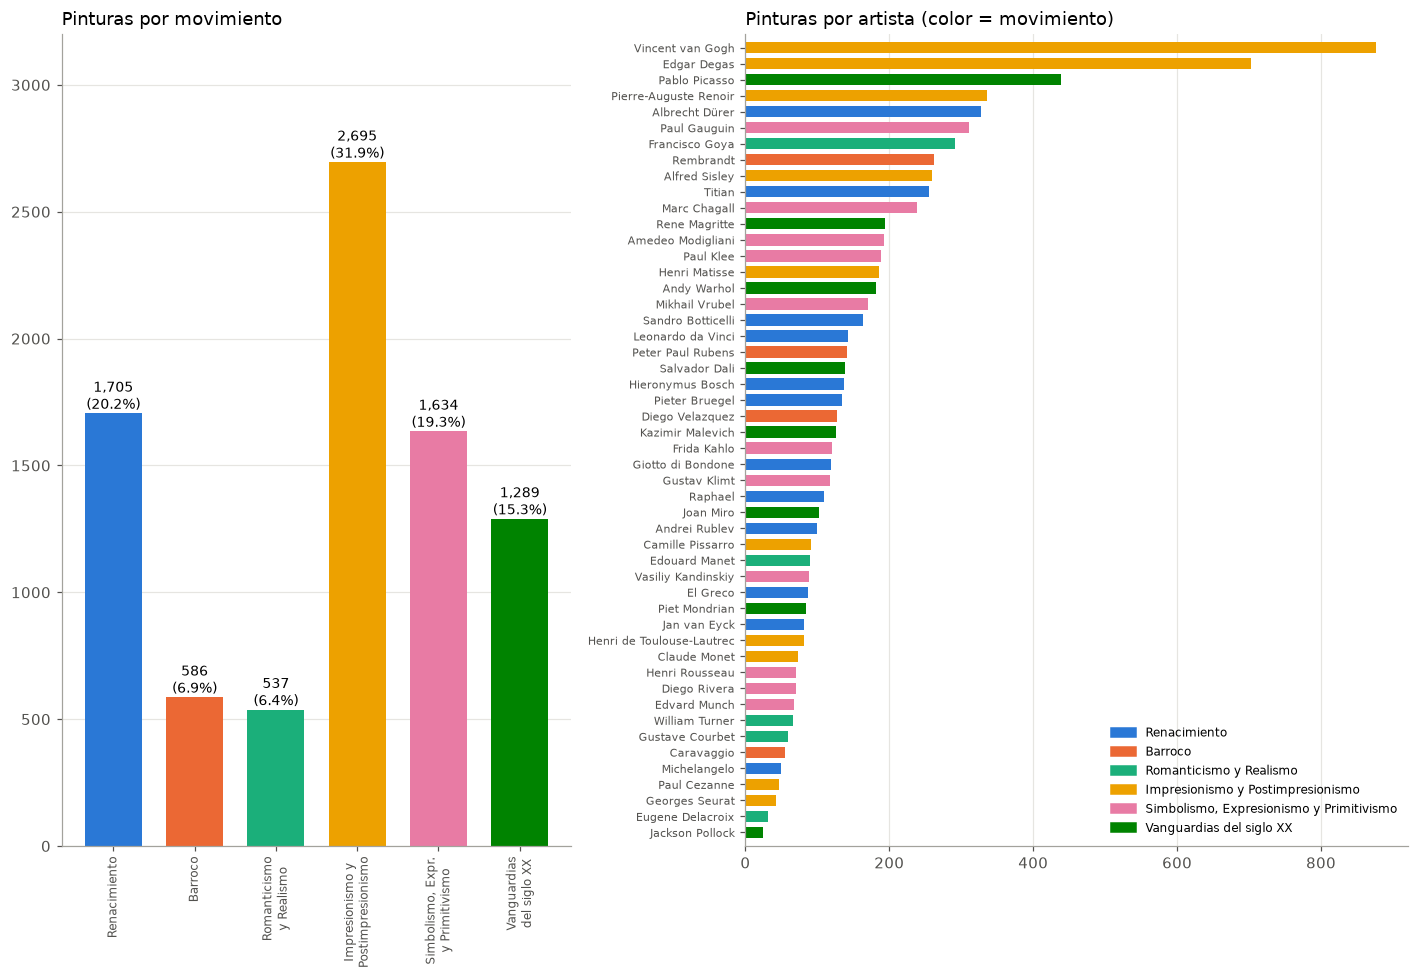

In [10]:
# Un color fijo por movimiento, en el mismo orden en todas las gráficas
MOVEMENT_COLORS = dict(zip(MOVEMENTS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]))
SHORT = {"Renacimiento": "Renacimiento", "Barroco": "Barroco", "Romanticismo y Realismo": "Romanticismo\ny Realismo",
         "Impresionismo y Postimpresionismo": "Impresionismo y\nPostimpresionismo",
         "Simbolismo, Expresionismo y Primitivismo": "Simbolismo, Expr.\ny Primitivismo",
         "Vanguardias del siglo XX": "Vanguardias\ndel siglo XX"}

total = paintings.count()
by_movement = (paintings.groupBy("movement")
               .agg(F.count("*").alias("paintings"), F.countDistinct("artist").alias("artists"))
               .withColumn("pct", F.round(F.col("paintings") / total * 100, 1)))
display(by_movement.orderBy(F.desc("paintings")))
by_artist = paintings.groupBy("artist", "movement").count().orderBy("count").collect()
mov_rows = {r["movement"]: r for r in by_movement.collect()}

fig, axes = plt.subplots(1, 2, figsize=(13, 9), gridspec_kw={"width_ratios": [1, 1.3]})
ax = axes[0]
bars = ax.bar([SHORT[m] for m in MOVEMENTS], [mov_rows[m]["paintings"] for m in MOVEMENTS],
              color=[MOVEMENT_COLORS[m] for m in MOVEMENTS], width=0.7)
ax.bar_label(bars, labels=[f'{mov_rows[m]["paintings"]:,}\n({mov_rows[m]["pct"]}%)' for m in MOVEMENTS], fontsize=9)
ax.set_title("Pinturas por movimiento", loc="left")
ax.tick_params(axis="x", labelsize=8, rotation=90)
ax.grid(axis="x", visible=False)
ax.set_ylim(0, 3200)

ax = axes[1]
ax.barh([r["artist"] for r in by_artist], [r["count"] for r in by_artist],
        color=[MOVEMENT_COLORS[r["movement"]] for r in by_artist], height=0.7)
ax.set_title("Pinturas por artista (color = movimiento)", loc="left")
ax.tick_params(axis="y", labelsize=7.5)
ax.grid(axis="y", visible=False)
ax.margins(y=0.01)
handles = [plt.Rectangle((0, 0), 1, 1, color=MOVEMENT_COLORS[m]) for m in MOVEMENTS]
ax.legend(handles, MOVEMENTS, loc="lower right", fontsize=8, frameon=False)
plt.tight_layout()
plt.show()

De lo anterior, se puede observar que:

- Las clases están desbalanceadas: Impresionismo y Postimpresionismo tiene 2,695 pinturas (31.9%), cinco veces más que Romanticismo y Realismo (537 pinturas, 6.4%).
- Por artista, va de 877 pinturas (Van Gogh) a 24 (Pollock). Los 5 artistas con más obras reúnen el 31.8% del dataset y los 10 primeros, el 48.1%.
- Algunas clases dependen mucho de un solo artista: Goya es el 54% de Romanticismo y Realismo y Rembrandt el 45% del Barroco.

Esto tiene dos consecuencias para el modelo. Por un lado, si siempre contestara Impresionismo acertaría cerca del 32%, por lo que el accuracy por sí solo no dice mucho. Por eso utilizo pesos por clase, una línea base y métricas por clase. Por otro lado, en las clases que dependen de un artista, el modelo podría aprender su estilo personal y no el del movimiento.

### 3.3 Nacionalidad, siglo y tamaño de las imágenes

Después, reviso la nacionalidad y el siglo de los artistas, junto con el tamaño y la proporción de las imágenes.

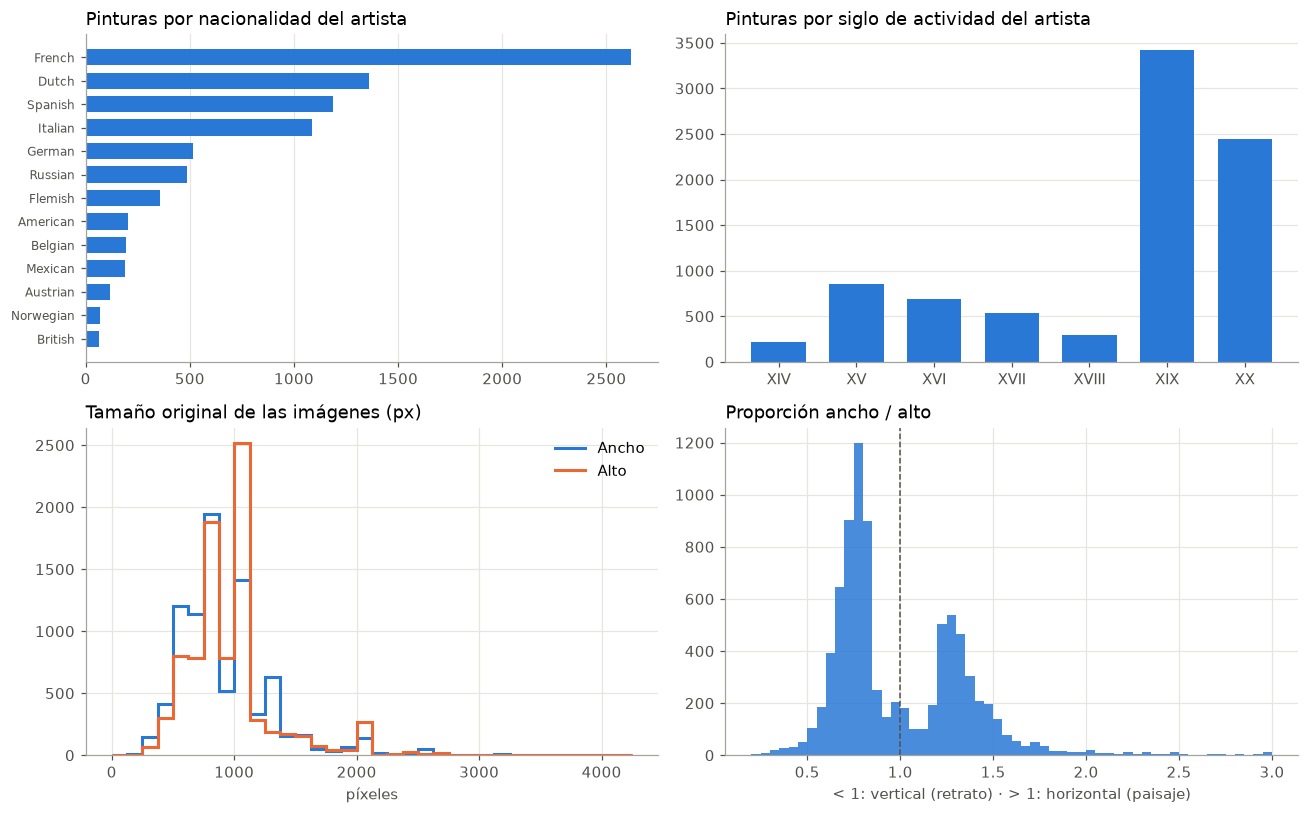

pct_vertical,pct_horizontal,min_width,max_width
60.1,39.7,204.0,4096.0


In [11]:
by_nat = paintings.groupBy("nationality").count().orderBy(F.desc("count")).collect()
by_century = paintings.groupBy("century").count().orderBy("century").collect()
size_stats = paintings.select("width", "height", "aspect_ratio")

fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
ax = axes[0, 0]
ax.barh([r["nationality"] for r in by_nat][::-1], [r["count"] for r in by_nat][::-1], color="#2a78d6", height=0.7)
ax.set_title("Pinturas por nacionalidad del artista", loc="left")
ax.tick_params(axis="y", labelsize=8)
ax.grid(axis="y", visible=False)

ax = axes[0, 1]
ROMAN = {14: "XIV", 15: "XV", 16: "XVI", 17: "XVII", 18: "XVIII", 19: "XIX", 20: "XX"}
ax.bar([ROMAN[r["century"]] for r in by_century], [r["count"] for r in by_century], color="#2a78d6", width=0.7)
ax.set_title("Pinturas por siglo de actividad del artista", loc="left")
ax.grid(axis="x", visible=False)

# Histogramas calculados en Spark: se cuenta cuántas imágenes caen en cada intervalo
def spark_hist(col, edges):
    bucket = F.least(F.greatest(F.floor((F.col(col) - edges[0]) / (edges[1] - edges[0])), F.lit(0)), F.lit(len(edges) - 2))
    counts = dict(paintings.groupBy(bucket.alias("b")).count().collect())
    return [counts.get(i, 0) for i in range(len(edges) - 1)]

edges_px = np.arange(0, 4251, 125)
ax = axes[1, 0]
for col, color, label in [("width", "#2a78d6", "Ancho"), ("height", "#eb6834", "Alto")]:
    ax.stairs(spark_hist(col, edges_px), edges_px, color=color, linewidth=2, label=label)
ax.set_title("Tamaño original de las imágenes (px)", loc="left")
ax.set_xlabel("píxeles")
ax.legend(frameon=False)

edges_ar = np.arange(0.2, 3.01, 0.05)
ax = axes[1, 1]
ax.stairs(spark_hist("aspect_ratio", edges_ar), edges_ar, color="#2a78d6", fill=True, alpha=0.85)
ax.axvline(1, color="#52514e", linewidth=1, linestyle="--")
ax.set_title("Proporción ancho / alto", loc="left")
ax.set_xlabel("< 1: vertical (retrato) · > 1: horizontal (paisaje)")
plt.tight_layout()
plt.show()

display(size_stats.select(F.round(F.avg((F.col("aspect_ratio") < 1).cast("int")) * 100, 1).alias("pct_vertical"),
                          F.round(F.avg((F.col("aspect_ratio") > 1).cast("int")) * 100, 1).alias("pct_horizontal"),
                          F.min("width").alias("min_width"), F.max("width").alias("max_width")))

De lo anterior, se puede observar que:

- Cuatro nacionalidades reúnen el 74.0% de las pinturas: francesa (31.0%), holandesa (16.1%), española (14.0%) e italiana (12.9%).
- Los siglos XIX y XX concentran el 69.4% de las obras.
- El siglo casi define la clase: todas las obras del siglo XV son del Renacimiento y todas las del siglo XVII son del Barroco.
- La mediana del tamaño es de 811 × 939 px, con una cola larga de imágenes grandes.
- El 60.1% de las imágenes son verticales y el 39.7% horizontales, con dos picos cerca de 0.75 (retrato) y de 1.25 (paisaje).

Con esto, el dataset es una selección de 50 artistas y no una muestra de toda la historia del arte, por lo que los resultados sólo valen para esa selección.

También decidí no utilizar la nacionalidad ni el siglo en el modelo, ya que quiero clasificar a partir de la imagen y esos datos casi delatan la respuesta. La proporción sí la utilizo, ya que distingue un retrato de un paisaje.

### 3.4 Color y textura por movimiento

Para saber si los rasgos cambian entre movimientos, comparo seis de ellos con diagramas de caja. Calculo los percentiles en Spark con `percentile_approx`, y los bigotes llegan a los percentiles 5 y 95.

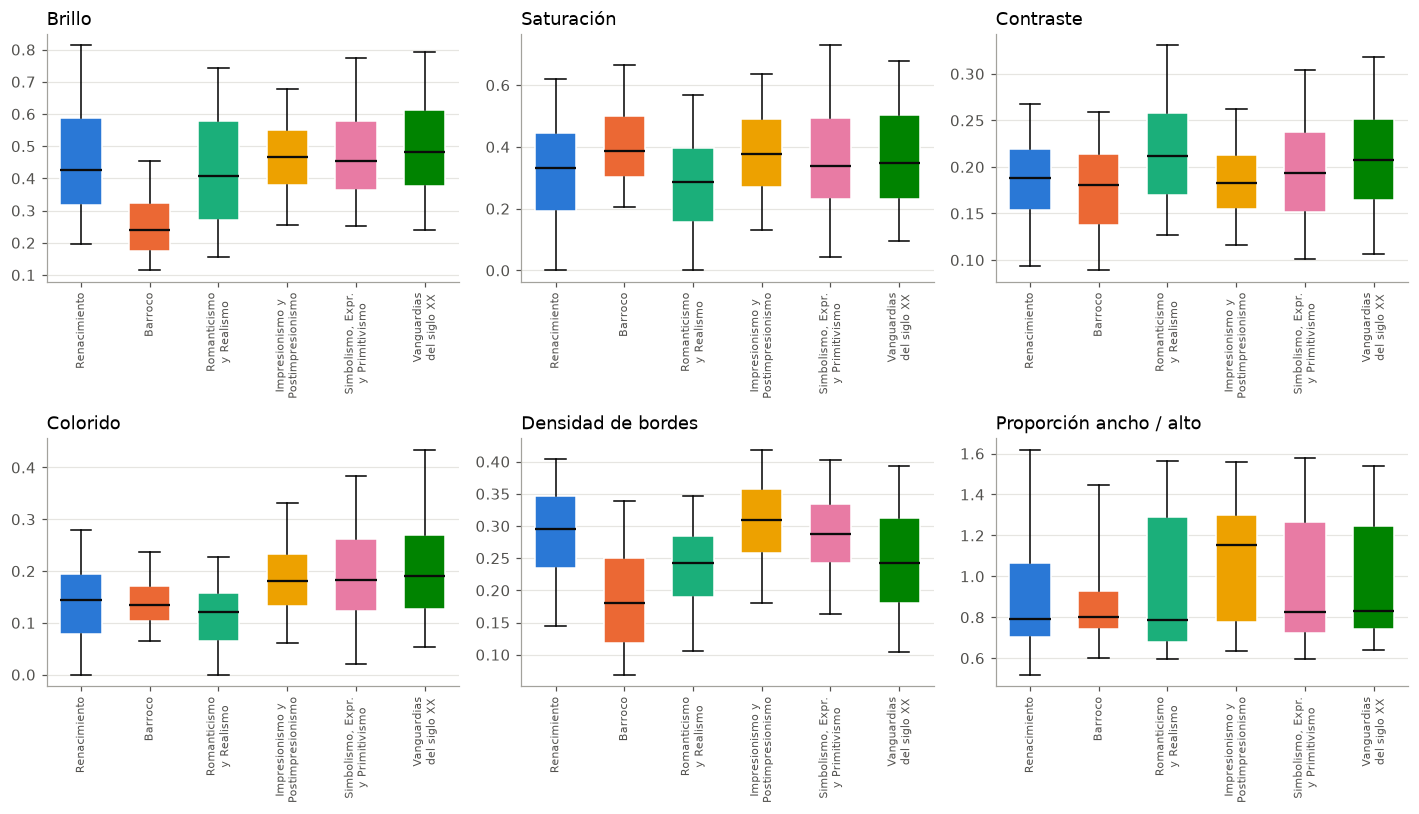

In [12]:
BOX_FEATURES = {"brightness": "Brillo", "s_mean": "Saturación", "contrast": "Contraste",
                "colorfulness": "Colorido", "edge_density": "Densidad de bordes", "aspect_ratio": "Proporción ancho / alto"}
quantiles = {r["movement"]: r for r in
             paintings.groupBy("movement")
                      .agg(*[F.percentile_approx(c, [0.05, 0.25, 0.5, 0.75, 0.95], 10000).alias(c) for c in BOX_FEATURES])
                      .collect()}

fig, axes = plt.subplots(2, 3, figsize=(13, 7.5))
for ax, (col, title) in zip(axes.ravel(), BOX_FEATURES.items()):
    stats = [{"label": SHORT[m], "whislo": quantiles[m][col][0], "q1": quantiles[m][col][1],
              "med": quantiles[m][col][2], "q3": quantiles[m][col][3], "whishi": quantiles[m][col][4]}
             for m in MOVEMENTS]
    box = ax.bxp(stats, showfliers=False, patch_artist=True, widths=0.6,
                 medianprops={"color": "#0b0b0b", "linewidth": 1.5})
    for patch, m in zip(box["boxes"], MOVEMENTS):
        patch.set_facecolor(MOVEMENT_COLORS[m])
        patch.set_edgecolor("white")
    ax.set_title(title, loc="left")
    ax.tick_params(axis="x", labelsize=7, rotation=90)
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

Las medianas de cada movimiento son las siguientes:

| Mediana | Renacimiento | Barroco | Romanticismo | Impresionismo | Simbolismo | Vanguardias |
|---|---|---|---|---|---|---|
| Brillo | 0.43 | 0.24 | 0.41 | 0.47 | 0.45 | 0.48 |
| Saturación | 0.33 | 0.39 | 0.29 | 0.38 | 0.34 | 0.35 |
| Contraste | 0.19 | 0.18 | 0.21 | 0.18 | 0.19 | 0.21 |
| Colorido | 0.14 | 0.14 | 0.12 | 0.18 | 0.18 | 0.19 |
| Densidad de bordes | 0.30 | 0.18 | 0.24 | 0.31 | 0.29 | 0.24 |
| Proporción | 0.79 | 0.80 | 0.79 | 1.16 | 0.82 | 0.83 |

De lo anterior, se puede observar que:

- El Barroco es el más oscuro, con una mediana de brillo de 0.24 contra 0.41 a 0.48 del resto, lo cual coincide con su claroscuro.
- Romanticismo y Realismo tiene la saturación más baja, en buena parte por los grabados de Goya (su mediana es de 0.22 y la del resto de la clase, de 0.35). El Barroco tiene la más alta ya que, aunque sus pinturas son oscuras, sus tonos cálidos están saturados.
- El contraste casi no cambia (de 0.18 a 0.21) y las cajas se enciman, por lo que por sí solo separa poco.
- El colorido es menor en Renacimiento, Barroco y Romanticismo y Realismo (de 0.12 a 0.14) que en los tres movimientos modernos (de 0.18 a 0.19).
- La densidad de bordes va de 0.18 en el Barroco, que tiene grandes zonas lisas, a 0.31 en Impresionismo, por su pincelada visible. El Renacimiento también es alto (0.30) por su detalle fino, y no se debe sólo a los grabados de Durero, ya que sin él la mediana sigue igual.
- Impresionismo y Postimpresionismo es el único con una mediana de proporción mayor a 1 (1.16) y con mayoría de obras horizontales (53%), ya que abundan los paisajes.

Esto confirma que tiene sentido clasificar con estos rasgos. Sin embargo, ninguno separa por sí solo a los seis movimientos, ya que las cajas se enciman, por lo que el modelo tiene que combinar varios rasgos a la vez.

También puedo anticipar que el Barroco será más fácil de reconocer que Romanticismo y Realismo, que mezcla óleos y grabados y se encima con otros movimientos.

Además, comparo la paleta de cada movimiento con su histograma de tono promedio, junto con su color promedio y su porcentaje de pinturas neutras (con saturación promedio menor a 0.12).

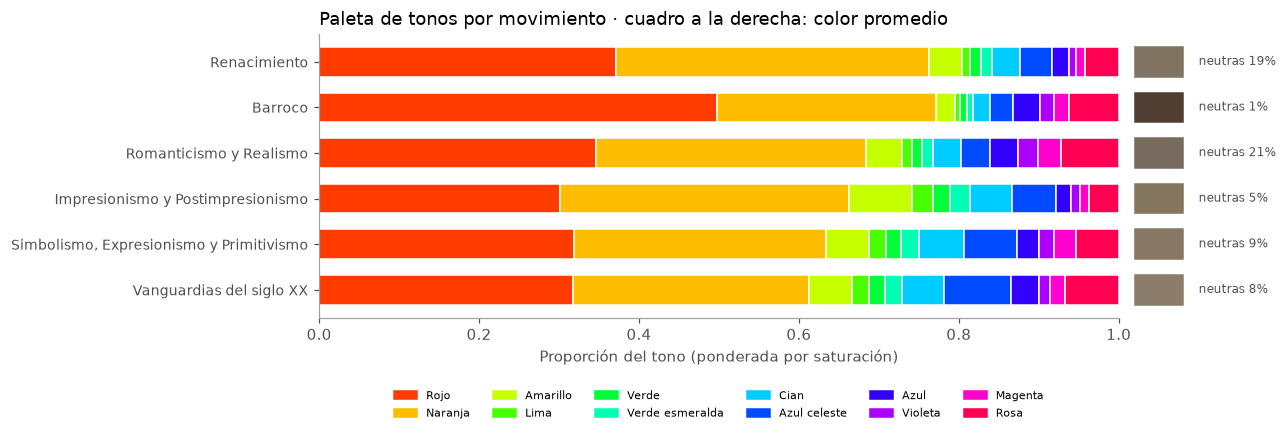

In [13]:
# Paleta de cada movimiento: histograma de tono promedio (solo pinturas con algo de color),
# color promedio y porcentaje de pinturas neutras (dibujos, grabados, tonos apagados)
has_color = F.col("hue_00").isNotNull() & (sum(F.col(c) for c in HUE_COLS) > 0)
palette = {r["movement"]: r for r in
           paintings.groupBy("movement")
                    .agg(*[F.avg(F.when(has_color, F.col(c))).alias(c) for c in HUE_COLS],
                         *[F.avg(c).alias(c) for c in ["r_mean", "g_mean", "b_mean"]],
                         F.avg((F.col("dominant_hue") == "Neutro").cast("int")).alias("neutral_share"))
                    .collect()}
hue_colors = [plt.cm.hsv((i + 0.5) / N_HUE_BINS) for i in range(N_HUE_BINS)]

fig, ax = plt.subplots(figsize=(12, 4.2))
for y, m in enumerate(MOVEMENTS[::-1]):
    left = 0
    for c, color in zip(HUE_COLS, hue_colors):
        ax.barh(y, palette[m][c], left=left, color=color, height=0.65, edgecolor="white", linewidth=1)
        left += palette[m][c]
    mean_rgb = (palette[m]["r_mean"], palette[m]["g_mean"], palette[m]["b_mean"])
    ax.add_patch(plt.Rectangle((1.02, y - 0.325), 0.06, 0.65, color=mean_rgb, clip_on=False))
    ax.text(1.10, y, f'neutras {palette[m]["neutral_share"]:.0%}', va="center", fontsize=8, color="#52514e")
ax.set_yticks(range(len(MOVEMENTS)), MOVEMENTS[::-1], fontsize=9)
ax.set_xlim(0, 1)
ax.set_xlabel("Proporción del tono (ponderada por saturación)")
ax.set_title("Paleta de tonos por movimiento · cuadro a la derecha: color promedio", loc="left")
ax.grid(False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in hue_colors]
ax.legend(handles, HUE_NAMES, ncol=6, fontsize=7.5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.22))
plt.tight_layout()
plt.show()

De lo anterior, se puede observar que:

- Los rojos y naranjas suman entre 61% y 77% en todos los movimientos, por los ocres y marrones de los pigmentos tradicionales. El máximo está en el Barroco (77%) y el Renacimiento (76%).
- Las franjas de lima a azul suben de 11% en el Barroco a 23% en las vanguardias.
- Las pinturas neutras son 21% en Romanticismo y Realismo y 19% en Renacimiento, por los dibujos y grabados, contra 1% en el Barroco.

Las diferencias de paleta existen, pero son graduales, por lo que las 12 franjas de tono entran al modelo como complemento de los demás rasgos.

### 3.5 Correlación entre rasgos

Ahora, reviso qué tan redundantes son los rasgos. Para esto, calculo la matriz de correlación de Pearson con `Correlation.corr` de MLlib.

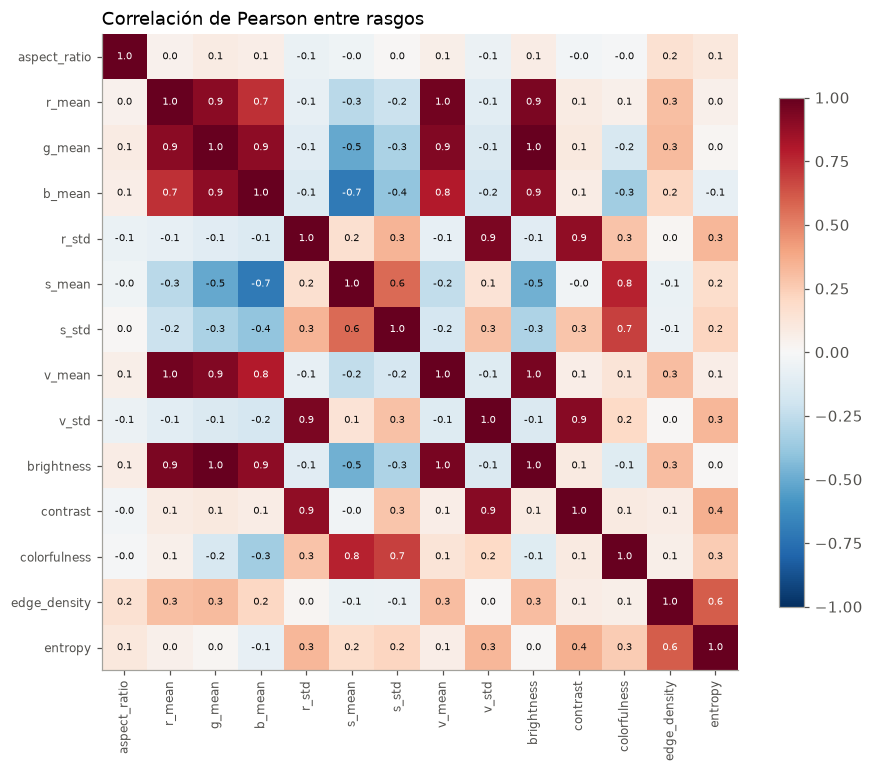

In [14]:
CORR_COLS = ["aspect_ratio", "r_mean", "g_mean", "b_mean", "r_std", "s_mean", "s_std", "v_mean", "v_std",
             "brightness", "contrast", "colorfulness", "edge_density", "entropy"]
corr_vec = VectorAssembler(inputCols=CORR_COLS, outputCol="v").transform(paintings).select("v")
corr = Correlation.corr(corr_vec, "v").first()[0].toArray()

fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(CORR_COLS)), CORR_COLS, rotation=90, fontsize=8)
ax.set_yticks(range(len(CORR_COLS)), CORR_COLS, fontsize=8)
for i in range(len(CORR_COLS)):
    for j in range(len(CORR_COLS)):
        ax.text(j, i, f"{corr[i, j]:.1f}", ha="center", va="center", fontsize=6.5,
                color="white" if abs(corr[i, j]) > 0.6 else "#0b0b0b")
ax.grid(False)
ax.set_title("Correlación de Pearson entre rasgos", loc="left")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

De lo anterior, se puede observar que:

- `r_mean`, `g_mean`, `b_mean`, `v_mean` y `brightness` miden casi lo mismo (de 0.7 a 1.0).
- `contrast`, `v_std` y `r_std` también van juntos (0.9).
- `colorfulness` sube con `s_mean` (0.8) y con `s_std` (0.7), mientras que `s_mean` baja cuando sube `b_mean` (-0.7).
- `edge_density` y `entropy` tienen una relación moderada (0.6).
- `aspect_ratio` casi no se relaciona con ningún rasgo (0.2 como máximo), por lo que aporta información propia.

Aunque muchos rasgos son redundantes, decidí conservarlos, ya que el Random Forest elige uno en cada corte. Sin embargo, su importancia se reparte entre los rasgos parecidos, por lo que hay que leer con cuidado las importancias de la sección 5.

### 3.6 Ejemplos de cada movimiento

Por último, reviso cuatro pinturas al azar de cada movimiento, para comparar los números con las obras reales.

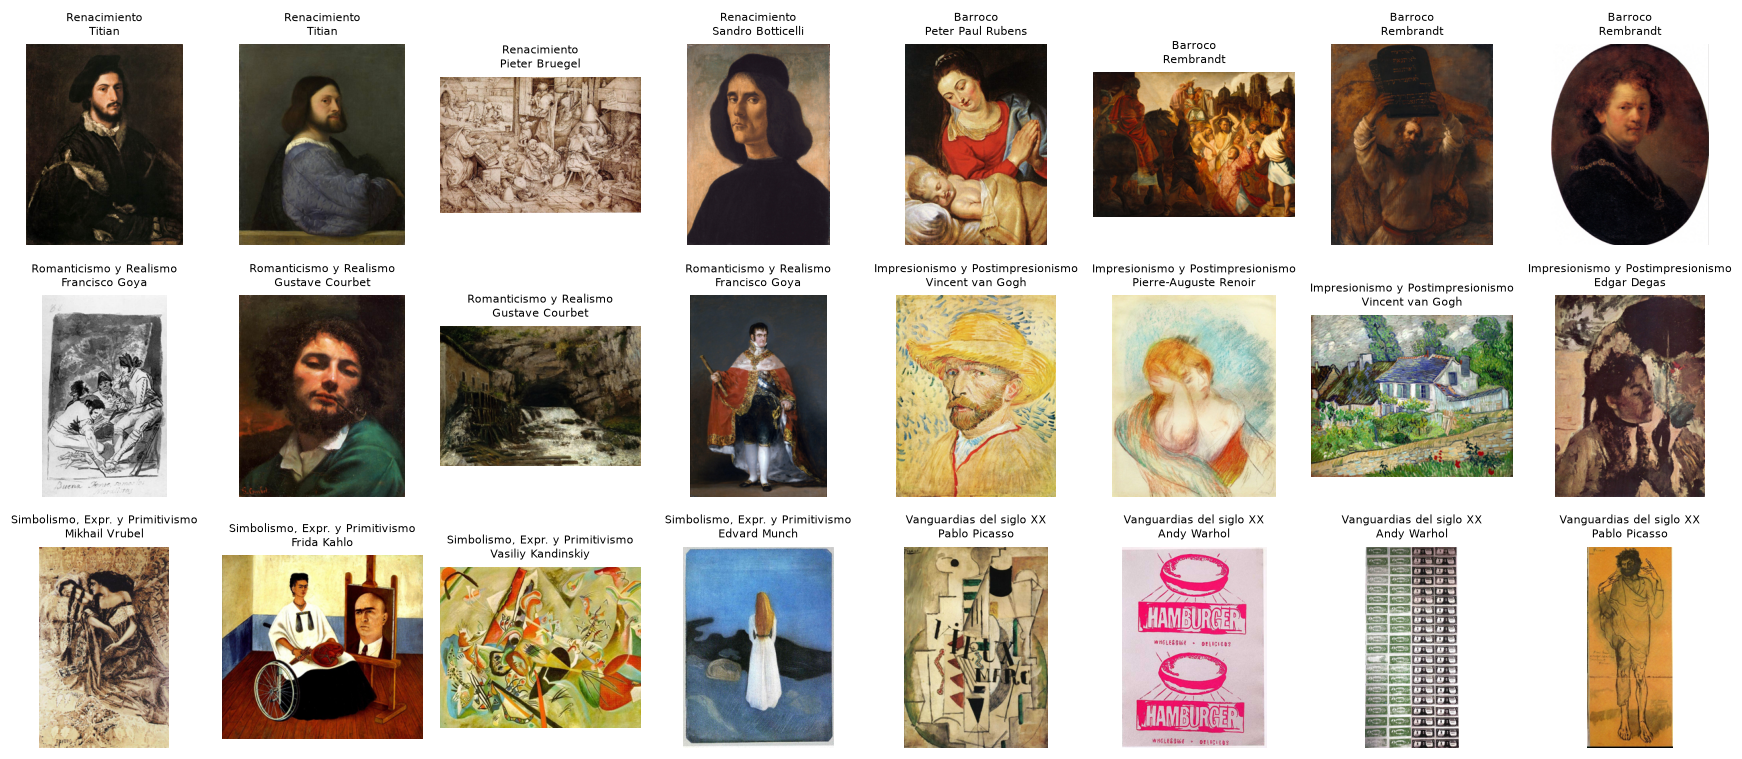

In [15]:
def local_path(path):
    return path.replace("file:", "", 1)


def show_thumbnails(rows, ncols, caption, figsize):
    # Dibuja una cuadrícula de miniaturas; caption(row) da el texto debajo de cada imagen
    nrows = int(np.ceil(len(rows) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    for ax in np.atleast_1d(axes).ravel():
        ax.axis("off")
    for ax, row in zip(np.atleast_1d(axes).ravel(), rows):
        img = Image.open(local_path(row["path"]))
        img.draft("RGB", (300, 300))
        img = img.convert("RGB")
        img.thumbnail((300, 300))
        ax.imshow(img)
        ax.set_title(caption(row), fontsize=7.5)
    plt.tight_layout()
    plt.show()


w = Window.partitionBy("movement").orderBy(F.rand(SEED))
samples = (paintings.withColumn("rn", F.row_number().over(w)).filter(F.col("rn") <= 4)
           .select("movement", "artist", "path").collect())
samples = sorted(samples, key=lambda r: MOVEMENTS.index(r["movement"]))
show_thumbnails(samples, 8, lambda r: f'{SHORT[r["movement"]].replace(chr(10), " ")}\n{r["artist"]}', (16, 7))

En las obras se ven las mismas diferencias que en los números: fondos oscuros en el Barroco, pincelada suelta en Impresionismo y colores más vivos en los movimientos modernos. Sin embargo, dentro de una misma clase hay óleos, dibujos y obras gráficas, y dos retratos de movimientos distintos pueden parecerse mucho.

Esta es la principal limitación de mi enfoque, ya que los rasgos globales de color y textura no saben qué está pintado.

### 3.7 Del EDA al modelo

Para cerrar el EDA, resumo qué decisión salió de cada hallazgo.

Primero, como encontré 328 copias exactas de Durero en una carpeta duplicada, quité los duplicados por SHA-1 antes de modelar (sección 2.2).

Después, como el tamaño de las imágenes varía mucho y depende del escaneo, reduje cada imagen a 256 px y no utilicé el ancho ni el alto como rasgos (secciones 2.2 y 4.1). Tampoco utilicé la nacionalidad ni el siglo, ya que casi delatan el movimiento, por lo que sólo usé rasgos de la imagen (sección 4.1).

Como las clases están desbalanceadas (31.9% contra 6.4%), utilicé pesos por clase, una línea base de clase mayoritaria, el F1 ponderado y métricas por clase (secciones 4.1 y 5).

Como los rasgos tienen escalas distintas, ya que la entropía llega casi a 8 y los demás rasgos de color y textura no pasan de 1, agregué un `StandardScaler` al `Pipeline` (sección 4.2).

Como ningún rasgo separa por sí solo a los seis movimientos, comparé un modelo lineal contra un Random Forest, que combina rasgos (sección 4.2).

Aunque muchos rasgos están muy correlacionados, los conservé y leí sus importancias con cuidado (secciones 4.1 y 5).

La proporción tiene dos picos y casi no se relaciona con otros rasgos, por lo que la incluí como rasgo del modelo. También incluí las 12 franjas de tono, ya que cada movimiento tiene una paleta distinta (sección 4.1).

Por último, como pocos artistas dominan algunas clases (Goya es el 54% de Romanticismo y Realismo), lo declaré como limitación y probé el modelo con pintores nuevos (secciones 5.1 y 6.3).


## 4. Modelo de clasificación con MLlib

### 4.1 Preparación

Para el modelo, la etiqueta es el movimiento (6 clases) y utilizo 28 rasgos: la proporción, 15 de color y textura y 12 del histograma de tono.

Separo los datos en `train`, `validation` y `test` (70/15/15) con un hash: el `xxhash64` del SHA-1 de cada pintura da un número de 0 a 99. Si es menor a 70 va a `train`, de 70 a 84 a `validation` y de 85 en adelante a `test`. Decidí hacerlo así ya que cada pintura cae siempre en el mismo conjunto, sin importar cómo reparta Spark las filas. Con `randomSplit` o `sampleBy`, en cambio, el resultado depende de ese reparto.

Cada conjunto tiene un papel distinto. Con `train` entreno los modelos y elijo sus hiperparámetros con validación cruzada, con `validation` comparo los candidatos y elijo el ganador, y `test` lo abro una sola vez, en la sección 5, con el modelo ya elegido.

Como las clases están desbalanceadas, le doy a cada pintura un peso de `pinturas de train / (clases × pinturas de su clase en train)`. Así, una pintura de una clase chica pesa más y el modelo no ignora esos movimientos. Calculo los pesos sólo con `train`, para que `validation` y `test` no influyan en el entrenamiento.

In [16]:
FEATURE_COLS = ["aspect_ratio", "r_mean", "g_mean", "b_mean", "r_std", "g_std", "b_std", "s_mean", "s_std",
                "v_mean", "v_std", "brightness", "contrast", "colorfulness", "edge_density", "entropy"] + HUE_COLS
LABEL_COL = "movement"

n_classes = len(MOVEMENTS)
bucket = F.pmod(F.xxhash64("sha1", F.lit(SEED)), F.lit(100))
data = paintings.withColumn("split", F.when(bucket < 70, "train").when(bucket < 85, "validation").otherwise("test"))

# Los pesos salen solo de train, para que validation y test no influyan en el entrenamiento
train_rows = data.filter(F.col("split") == "train")
class_weights = train_rows.groupBy(LABEL_COL).agg((F.lit(train_rows.count()) / (F.count("*") * n_classes)).alias("weight"))
data = data.join(class_weights, LABEL_COL)

train = data.filter(F.col("split") == "train").cache()
validation = data.filter(F.col("split") == "validation").cache()
test = data.filter(F.col("split") == "test").cache()
print(f"Train: {train.count():,} | Validation: {validation.count():,} | Test: {test.count():,}")

split_counts = (data.groupBy(LABEL_COL).pivot("split", ["train", "validation", "test"]).count()
                .join(class_weights, LABEL_COL)
                .withColumn("validation_pct", F.round(F.col("validation") / (F.col("train") + F.col("validation") + F.col("test")) * 100, 1))
                .withColumn("test_pct", F.round(F.col("test") / (F.col("train") + F.col("validation") + F.col("test")) * 100, 1))
                .withColumn("weight", F.round("weight", 3)))
display(split_counts.orderBy(F.desc("train")))

Train: 5,909 | Validation: 1,252 | Test: 1,285


movement,train,validation,test,weight,validation_pct,test_pct
Impresionismo y Postimpresionismo,1898,399,398,0.519,14.8,14.8
Renacimiento,1179,242,284,0.835,14.2,16.7
"Simbolismo, Expresionismo y Primitivismo",1126,245,263,0.875,15.0,16.1
Vanguardias del siglo XX,907,199,183,1.086,15.4,14.2
Barroco,415,89,82,2.373,15.2,14.0
Romanticismo y Realismo,384,78,75,2.565,14.5,14.0


Quedaron 5,909 pinturas en `train`, 1,252 en `validation` y 1,285 en `test`. Aunque el hash no depende del movimiento, cada clase quedó cerca del 15% tanto en `validation` (de 14.2% a 15.4%) como en `test` (de 14.0% a 16.7%). Los pesos van de 0.519 en Impresionismo y Postimpresionismo a 2.565 en Romanticismo y Realismo.

### 4.2 Pipeline y comparación de modelos

Ahora, armo un `Pipeline` con cuatro etapas:

1. `StringIndexer` convierte el movimiento en `label` (0 es la clase más frecuente).
2. `VectorAssembler` junta los 28 rasgos en `features_raw`.
3. `StandardScaler` escala cada rasgo, para que la regresión logística no favorezca a los que tienen una escala grande.
4. El clasificador.

Todo se ajusta sólo con `train`, por lo que ninguna etapa ve `validation` ni `test`.

Comparo en `validation` una regresión logística multinomial y un Random Forest, y tomo como referencia una línea base que siempre predice la clase más frecuente.

In [17]:
label_indexer = StringIndexer(inputCol=LABEL_COL, outputCol="label")
assembler = VectorAssembler(inputCols=FEATURE_COLS, outputCol="features_raw")
scaler = StandardScaler(inputCol="features_raw", outputCol="features", withMean=True, withStd=True)

METRICS = ["accuracy", "f1", "weightedPrecision", "weightedRecall"]
evaluators = {m: MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName=m)
              for m in METRICS}


def evaluate(pred, name):
    return {"model": name, **{m: round(evaluators[m].evaluate(pred), 4) for m in METRICS}}


def metrics_table(rows):
    return spark.createDataFrame(rows).select("model", *METRICS)


lr = LogisticRegression(featuresCol="features", labelCol="label", weightCol="weight", maxIter=200, regParam=0.001)
rf = RandomForestClassifier(featuresCol="features", labelCol="label", weightCol="weight",
                            numTrees=100, maxDepth=10, seed=SEED)

start = time.time()
model_lr = Pipeline(stages=[label_indexer, assembler, scaler, lr]).fit(train)
model_rf = Pipeline(stages=[label_indexer, assembler, scaler, rf]).fit(train)
print(f"Entrenamiento de los dos modelos: {time.time() - start:.0f} s")

pred_lr = model_lr.transform(validation)
pred_rf = model_rf.transform(validation)
pred_baseline = model_rf.stages[0].transform(validation).withColumn("prediction", F.lit(0.0))   # 0 = clase mayoritaria

results = [evaluate(pred_baseline, "Línea base (clase mayoritaria)"),
           evaluate(pred_lr, "Regresión logística"),
           evaluate(pred_rf, "Random Forest")]
display(metrics_table(results))

Entrenamiento de los dos modelos: 13 s


model,accuracy,f1,weightedPrecision,weightedRecall
Línea base (clase mayoritaria),0.3187,0.154,0.1016,0.3187
Regresión logística,0.3962,0.3965,0.4182,0.3962
Random Forest,0.5176,0.5149,0.5227,0.5176


La línea base acierta el 31.9%, la regresión logística el 39.6% y el Random Forest el 51.8%. Que el Random Forest le gane por 12 puntos a la regresión logística indica que la relación entre los rasgos y el movimiento no es lineal. Por eso, es el modelo que voy a ajustar.

### 4.3 Ajuste de hiperparámetros

Pruebo 8 combinaciones de `numTrees`, `maxDepth` y `minInstancesPerNode` con validación cruzada de 3 *folds* sobre `train`, usando el F1 ponderado como métrica.

In [18]:
grid = (ParamGridBuilder()
        .addGrid(rf.numTrees, [100, 200])
        .addGrid(rf.maxDepth, [10, 15])
        .addGrid(rf.minInstancesPerNode, [1, 5])
        .build())

cv = CrossValidator(estimator=Pipeline(stages=[label_indexer, assembler, scaler, rf]),
                    estimatorParamMaps=grid, evaluator=evaluators["f1"],
                    numFolds=3, parallelism=1, seed=SEED)   # un modelo a la vez: cada Random Forest ya usa todos los núcleos
start = time.time()
cv_model = cv.fit(train)
print(f"Validación cruzada (8 combinaciones x 3 folds): {time.time() - start:.0f} s")

cv_results = spark.createDataFrame(
    [(p[rf.numTrees], p[rf.maxDepth], p[rf.minInstancesPerNode], round(float(f1), 4))
     for p, f1 in zip(grid, cv_model.avgMetrics)],
    ["numTrees", "maxDepth", "minInstancesPerNode", "cv_f1"])
display(cv_results.orderBy(F.desc("cv_f1")))

best_model = cv_model.bestModel
best_rf = best_model.stages[-1]
print("Mejor combinación:", best_rf.getNumTrees, "árboles | profundidad", best_rf.getMaxDepth(),
      "| minInstancesPerNode", best_rf.getMinInstancesPerNode())

Validación cruzada (8 combinaciones x 3 folds): 343 s


numTrees,maxDepth,minInstancesPerNode,cv_f1
200,15,1,0.5196
100,15,1,0.5174
100,15,5,0.5127
200,15,5,0.5127
100,10,1,0.5064
200,10,5,0.5043
200,10,1,0.5036
100,10,5,0.497


Mejor combinación: 200 árboles | profundidad 15 | minInstancesPerNode 1


La mejor combinación fue de 200 árboles, profundidad 15 y `minInstancesPerNode` de 1, con un F1 de 0.520. Las cuatro mejores combinaciones tienen profundidad 15, por lo que la profundidad pesa más que el número de árboles.

### 4.4 Comparación en validation

Ahora, comparo los cuatro candidatos en `validation`, que ninguno utilizó para entrenar ni para elegir hiperparámetros.

In [19]:
results.append(evaluate(best_model.transform(validation), "Random Forest ajustado (CV)"))
display(metrics_table(results))


model,accuracy,f1,weightedPrecision,weightedRecall
Línea base (clase mayoritaria),0.3187,0.154,0.1016,0.3187
Regresión logística,0.3962,0.3965,0.4182,0.3962
Random Forest,0.5176,0.5149,0.5227,0.5176
Random Forest ajustado (CV),0.5631,0.5505,0.5642,0.5631


El ganador fue el Random Forest ajustado, con un accuracy de 56.3% y un F1 ponderado de 0.551. Es decir, el ajuste subió el F1 de 0.515 a 0.551.

## 5. Evaluación

Una vez elegido el modelo, lo reentreno con `train` y `validation` juntos, con los hiperparámetros de la validación cruzada, para aprovechar esas pinturas. Después, lo evalúo en `test`, que hasta aquí no había utilizado ni para entrenar ni para decidir.

In [20]:
# El ganador se reentrena con train + validation, con los hiperparámetros que eligió la validación cruzada
best_params = grid[int(np.argmax(cv_model.avgMetrics))]
final_model = Pipeline(stages=[label_indexer, assembler, scaler, rf.copy(best_params)]).fit(train.union(validation))

pred_best = final_model.transform(test).cache()
pred_baseline_test = final_model.stages[0].transform(test).withColumn("prediction", F.lit(0.0))
test_results = [evaluate(pred_baseline_test, "Línea base (clase mayoritaria)"), evaluate(pred_best, "Modelo final")]
display(metrics_table(test_results))

# Precisión, recall y F1 por clase con las métricas ByLabel del evaluador
labels = final_model.stages[0].labels
support = dict(pred_best.groupBy("label").count().collect())


def by_label(metric, i):
    return MulticlassClassificationEvaluator(labelCol="label", metricName=metric, metricLabel=float(i)).evaluate(pred_best)


class_metrics = spark.createDataFrame(
    [(name, support[float(i)], round(by_label("precisionByLabel", i), 3), round(by_label("recallByLabel", i), 3),
      round(by_label("fMeasureByLabel", i), 3)) for i, name in enumerate(labels)],
    ["movement", "support", "precision", "recall", "f1"])
display(class_metrics.orderBy(F.desc("f1")))

model,accuracy,f1,weightedPrecision,weightedRecall
Línea base (clase mayoritaria),0.3097,0.1465,0.0959,0.3097
Modelo final,0.5549,0.5455,0.5594,0.5549


movement,support,precision,recall,f1
Impresionismo y Postimpresionismo,398,0.542,0.726,0.621
Renacimiento,284,0.599,0.588,0.593
Vanguardias del siglo XX,183,0.568,0.454,0.505
Barroco,82,0.451,0.561,0.5
"Simbolismo, Expresionismo y Primitivismo",263,0.57,0.418,0.482
Romanticismo y Realismo,75,0.562,0.24,0.336


El modelo final acierta el 55.5% de las pinturas de prueba (F1 ponderado de 0.546), contra 31.0% de la línea base, es decir, 1.8 veces más.

Los tres F1 son parecidos: 0.520 en validación cruzada, 0.551 en `validation` y 0.546 en `test`, por lo que la estimación es confiable. El de la validación cruzada es un poco menor, ya que cada modelo entrena sólo con dos tercios de `train`.

Por clase, Impresionismo y Postimpresionismo tiene el mejor recall (73%), seguido de Renacimiento (59%) y Barroco (56%). Romanticismo y Realismo es la clase más difícil, con un recall de 24%, aunque con sólo 75 pinturas en `test` este valor puede variar más.

Para ver a dónde se van los errores, calculo la matriz de confusión en porcentaje por fila.

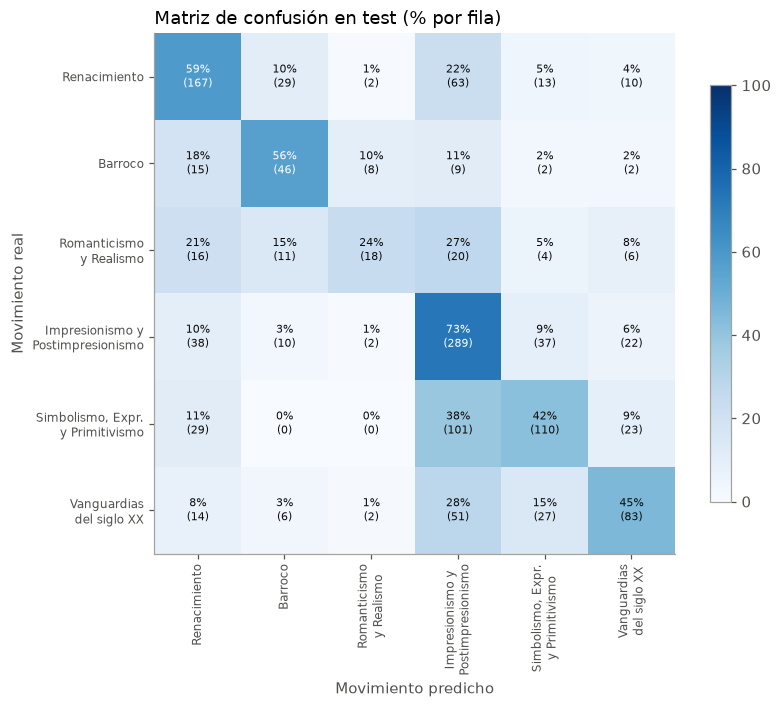

In [21]:
# Matriz de confusión normalizada por fila: qué porcentaje de cada movimiento real va a cada predicción
counts = {(int(r["label"]), int(r["prediction"])): r["count"]
          for r in pred_best.groupBy("label", "prediction").count().collect()}
order = [labels.index(m) for m in MOVEMENTS]
cm = np.array([[counts.get((i, j), 0) for j in order] for i in order], dtype=float)
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=100)
names = [SHORT[m] for m in MOVEMENTS]
ax.set_xticks(range(n_classes), names, rotation=90, fontsize=8)
ax.set_yticks(range(n_classes), names, fontsize=8)
for i in range(n_classes):
    for j in range(n_classes):
        ax.text(j, i, f"{cm_pct[i, j]:.0f}%\n({int(cm[i, j])})", ha="center", va="center", fontsize=7.5,
                color="white" if cm_pct[i, j] > 55 else "#0b0b0b")
ax.set_xlabel("Movimiento predicho")
ax.set_ylabel("Movimiento real")
ax.set_title("Matriz de confusión en test (% por fila)", loc="left")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

La columna de Impresionismo recibe entre 11% y 38% de las demás clases, y Simbolismo, Expresionismo y Primitivismo es la más afectada (38%). Al ser la clase más grande, funciona como destino por defecto cuando el modelo duda. Por su parte, los errores de Romanticismo y Realismo se reparten entre Impresionismo (27%) y Renacimiento (21%).

También reviso qué rasgos le sirvieron más al modelo.

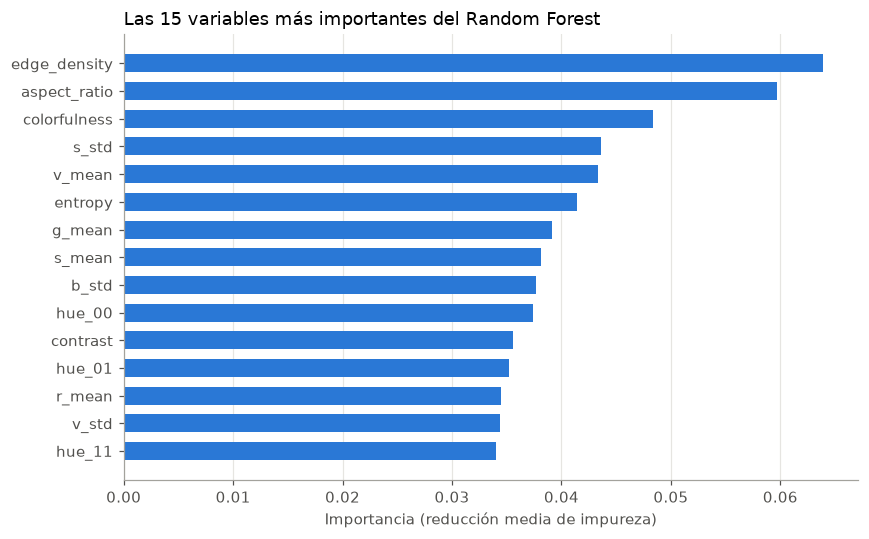

In [22]:
importances = spark.createDataFrame(
    [(name, round(float(v), 4)) for name, v in zip(FEATURE_COLS, final_model.stages[-1].featureImportances.toArray())],
    ["feature", "importance"]).orderBy(F.desc("importance"))
top = importances.limit(15).collect()[::-1]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh([r["feature"] for r in top], [r["importance"] for r in top], color="#2a78d6", height=0.65)
ax.set_title("Las 15 variables más importantes del Random Forest", loc="left")
ax.set_xlabel("Importancia (reducción media de impureza)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

Los más útiles son la densidad de bordes, la proporción y el colorido, seguidos de la variación de saturación y del brillo (`v_mean`), lo cual coincide con lo que vi en el EDA.

En las pinturas con las que entrenó, el modelo acierta el 99.0% (ver la sección 7), es decir, memoriza lo que ya vio. Por eso, la métrica que cuenta es la de prueba.

### 5.1 Limitaciones

Este modelo tiene tres limitaciones. Primero, hay pinturas de un mismo artista en los tres conjuntos, por lo que parte de lo aprendido es el estilo de cada artista y no sólo el del movimiento. Después, la etiqueta viene del artista y no de cada obra, así que todo Picasso cuenta como Vanguardias, aunque pintara cuadros figurativos en otras etapas. Por último, los rasgos son globales y no captan la composición ni los objetos representados, que es lo que distingue, por ejemplo, un retrato renacentista de uno barroco.

## 6. Predicciones

### 6.1 Guardar y recargar el modelo

Ahora, guardo el `PipelineModel` completo y lo recargo, para comprobar que da exactamente las mismas predicciones.

In [23]:
MODEL_PATH = f"{OUTPUT_DIR}/movement_model"

# [Colab] (Opcional) Guardar el modelo en Google Drive, porque /content se borra al cerrar la sesión
# from google.colab import drive
# drive.mount("/content/drive")
# MODEL_PATH = "/content/drive/MyDrive/movement_model"

final_model.write().overwrite().save(MODEL_PATH)
loaded_model = PipelineModel.load(MODEL_PATH)

pred_loaded = loaded_model.transform(test)
mismatches = (pred_best.select("sha1", F.col("prediction").alias("p1"))
              .join(pred_loaded.select("sha1", F.col("prediction").alias("p2")), "sha1")
              .filter(F.col("p1") != F.col("p2")).count())
print("Predicciones distintas entre el modelo original y el recargado:", mismatches)

Predicciones distintas entre el modelo original y el recargado: 0


No hubo ninguna predicción distinta entre el modelo original y el recargado, por lo que se guardó correctamente.

### 6.2 Ejemplos del conjunto de prueba

Después, reviso cuatro aciertos y cuatro errores al azar del conjunto de prueba, con la probabilidad que el modelo le asignó a su predicción.

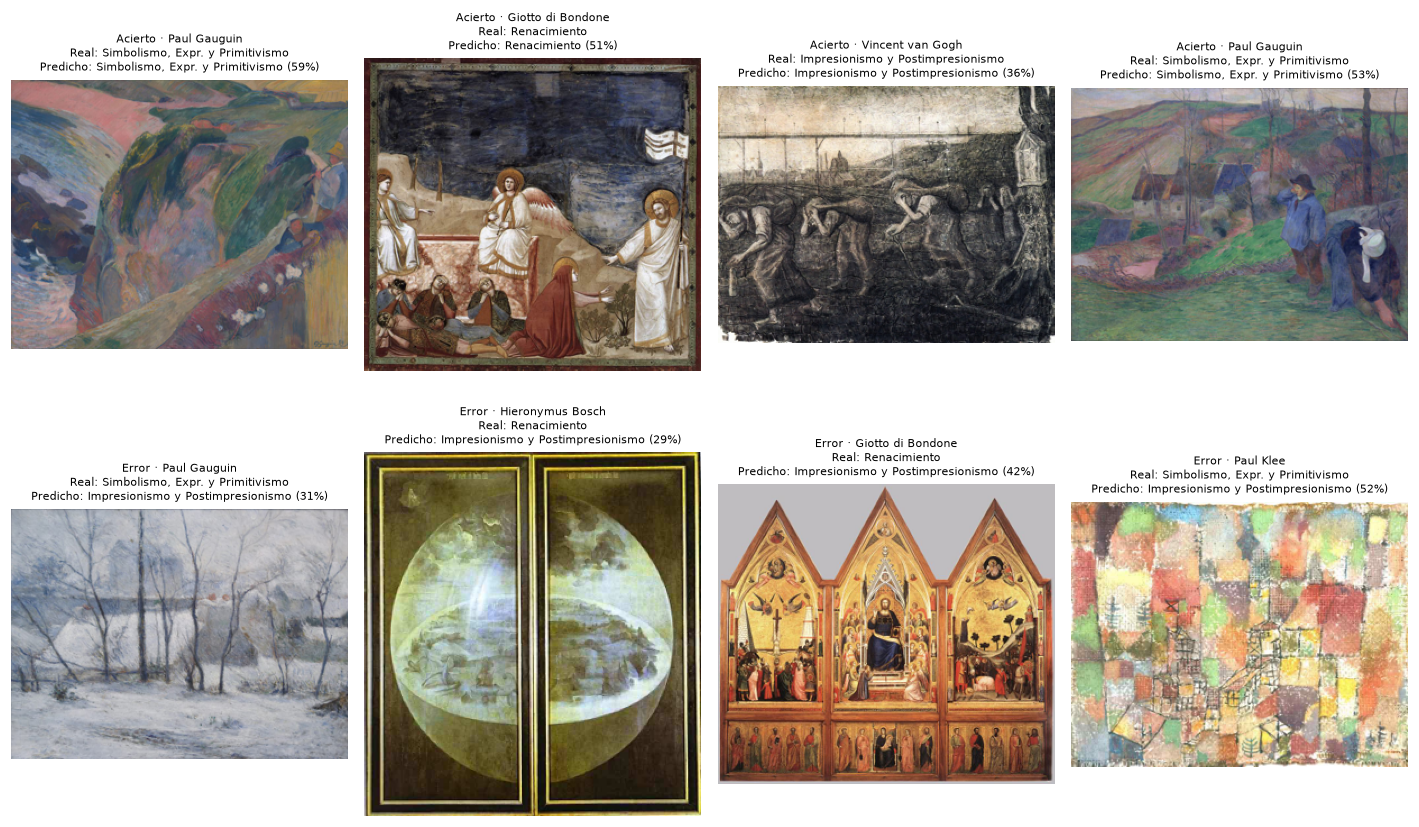

In [24]:
pred_view = (pred_loaded
             .withColumn("predicted_movement", F.element_at(F.array(*[F.lit(l) for l in labels]),
                                                            F.col("prediction").cast("int") + 1))
             .withColumn("confidence", F.array_max(vector_to_array("probability")))
             .withColumn("correct", F.col("prediction") == F.col("label")))

examples = (pred_view.filter("correct").orderBy(F.rand(SEED)).limit(4).collect()
            + pred_view.filter("NOT correct").orderBy(F.rand(SEED)).limit(4).collect())
show_thumbnails(examples, 4,
                lambda r: (f'{"Acierto" if r["correct"] else "Error"} · {r["artist"]}\n'
                           f'Real: {SHORT[r["movement"]].replace(chr(10), " ")}\n'
                           f'Predicho: {SHORT[r["predicted_movement"]].replace(chr(10), " ")} ({r["confidence"]:.0%})'),
                (13, 8))

En esta muestra, los cuatro errores cayeron en Impresionismo y Postimpresionismo, lo cual coincide con la matriz de confusión. Además, el modelo se equivocó incluso con obras muy distintas a un cuadro impresionista, como un retablo de Giotto, ya que no sabe qué está pintado.

### 6.3 Pinturas nuevas

Para una prueba más dura, descargué de Wikimedia Commons ocho pinturas de dominio público de artistas que no están en el dataset:

| Archivo | Obra | Movimiento esperado |
|---|---|---|
| `fra_angelico_annunciation.jpg` | Fra Angelico, *La Anunciación* (c. 1426) | Renacimiento |
| `vermeer_girl_with_a_pearl_earring.jpg` | Johannes Vermeer, *La joven de la perla* (c. 1665) | Barroco |
| `friedrich_wanderer_above_the_sea_of_fog.jpg` | Caspar David Friedrich, *El caminante sobre el mar de nubes* (1818) | Romanticismo y Realismo |
| `millet_the_gleaners.jpg` | Jean-François Millet, *Las espigadoras* (1857) | Romanticismo y Realismo |
| `morisot_the_cradle.jpg` | Berthe Morisot, *La cuna* (1872) | Impresionismo y Postimpresionismo |
| `redon_the_cyclops.jpg` | Odilon Redon, *El cíclope* (c. 1914) | Simbolismo, Expresionismo y Primitivismo |
| `schiele_self_portrait_with_physalis.jpg` | Egon Schiele, *Autorretrato con physalis* (1912) | Simbolismo, Expresionismo y Primitivismo |
| `gris_portrait_of_picasso.jpg` | Juan Gris, *Retrato de Pablo Picasso* (1912) | Vanguardias del siglo XX |

Para predecirlas, `predict_folder` aplica la misma extracción de rasgos del ETL (`build_features`) y el modelo recargado. Muestro los tres movimientos más probables de cada una.

file_name,expected,predicted,top_3
fra_angelico_annunciation.jpg,Renacimiento,Impresionismo y Postimpresionismo,"Impresionismo y Postimpresionismo 35% | Renacimiento 25% | Simbolismo, Expresionismo y Primitivismo 22%"
vermeer_girl_with_a_pearl_earring.jpg,Barroco,Renacimiento,Renacimiento 35% | Barroco 33% | Impresionismo y Postimpresionismo 13%
friedrich_wanderer_above_the_sea_of_fog.jpg,Romanticismo y Realismo,Vanguardias del siglo XX,Vanguardias del siglo XX 50% | Impresionismo y Postimpresionismo 26% | Romanticismo y Realismo 10%
millet_the_gleaners.jpg,Romanticismo y Realismo,Impresionismo y Postimpresionismo,Impresionismo y Postimpresionismo 28% | Vanguardias del siglo XX 25% | Romanticismo y Realismo 22%
morisot_the_cradle.jpg,Impresionismo y Postimpresionismo,Vanguardias del siglo XX,"Vanguardias del siglo XX 31% | Impresionismo y Postimpresionismo 25% | Simbolismo, Expresionismo y Primitivismo 19%"
redon_the_cyclops.jpg,"Simbolismo, Expresionismo y Primitivismo",Impresionismo y Postimpresionismo,"Impresionismo y Postimpresionismo 42% | Renacimiento 24% | Simbolismo, Expresionismo y Primitivismo 16%"
schiele_self_portrait_with_physalis.jpg,"Simbolismo, Expresionismo y Primitivismo","Simbolismo, Expresionismo y Primitivismo","Simbolismo, Expresionismo y Primitivismo 27% | Impresionismo y Postimpresionismo 27% | Vanguardias del siglo XX 23%"
gris_portrait_of_picasso.jpg,Vanguardias del siglo XX,Impresionismo y Postimpresionismo,"Impresionismo y Postimpresionismo 32% | Vanguardias del siglo XX 27% | Simbolismo, Expresionismo y Primitivismo 23%"


Aciertos: 1 de 8


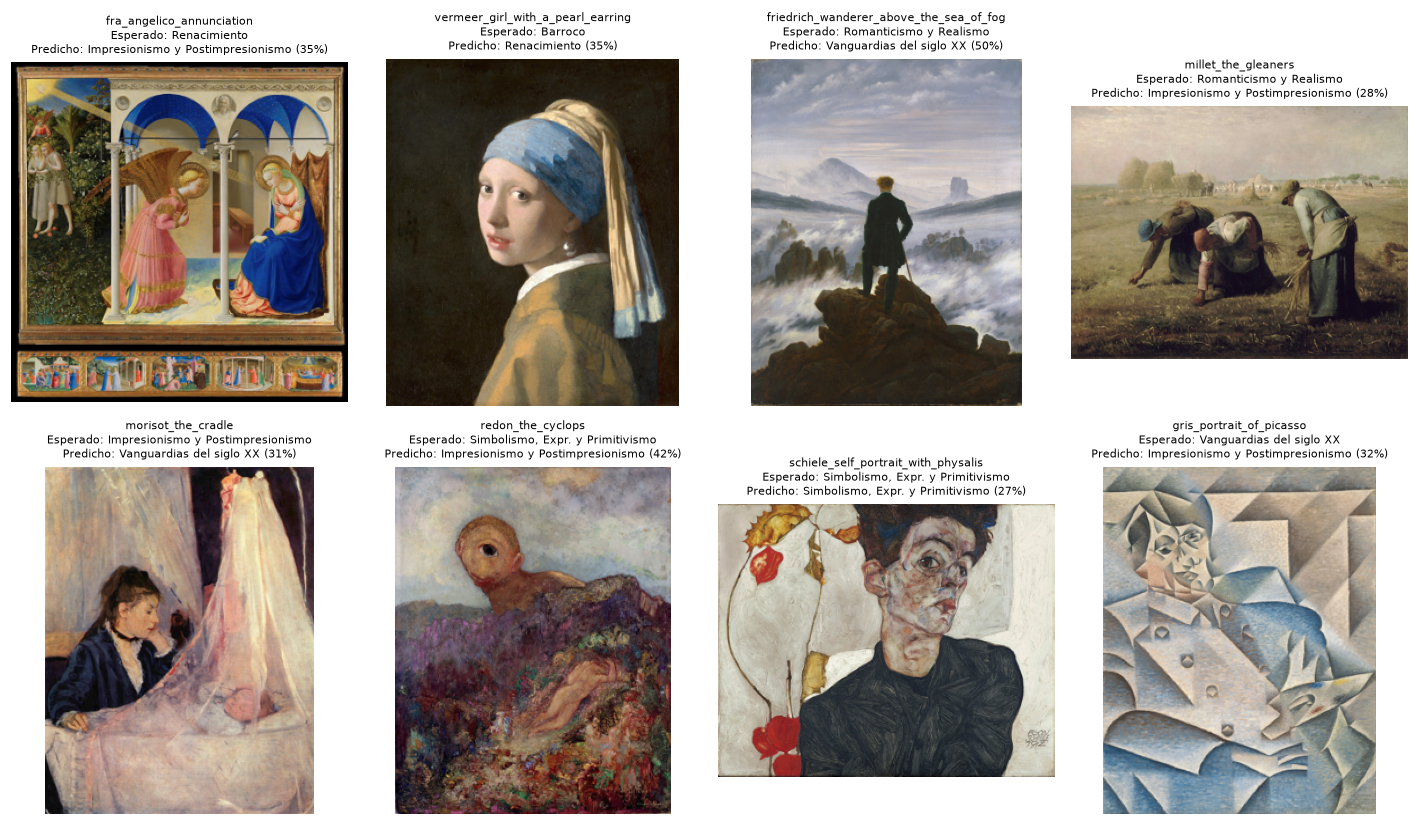

In [25]:
def predict_folder(folder, model):
    # Lee las imágenes de una carpeta, calcula sus rasgos y regresa predicción y probabilidades por imagen
    new = (spark.read.format("binaryFile").option("pathGlobFilter", "*.{jpg,jpeg,png}").load(folder)
           .withColumn("file_name", F.element_at(F.split("path", "/"), -1)))
    return (model.transform(build_features(new))
                 .withColumn("probs", vector_to_array("probability"))
                 .select("path", "file_name", "prediction", "probs"))


EXPECTED = {"fra_angelico_annunciation.jpg": "Renacimiento",
            "vermeer_girl_with_a_pearl_earring.jpg": "Barroco",
            "friedrich_wanderer_above_the_sea_of_fog.jpg": "Romanticismo y Realismo",
            "millet_the_gleaners.jpg": "Romanticismo y Realismo",
            "morisot_the_cradle.jpg": "Impresionismo y Postimpresionismo",
            "redon_the_cyclops.jpg": "Simbolismo, Expresionismo y Primitivismo",
            "schiele_self_portrait_with_physalis.jpg": "Simbolismo, Expresionismo y Primitivismo",
            "gris_portrait_of_picasso.jpg": "Vanguardias del siglo XX"}

new_preds = predict_folder(NEW_DIR, loaded_model).collect()
new_preds = sorted(new_preds, key=lambda r: MOVEMENTS.index(EXPECTED[r["file_name"]]))
new_table = spark.createDataFrame(
    [(r["file_name"], EXPECTED[r["file_name"]], labels[int(r["prediction"])],
      " | ".join(f"{m} {p:.0%}" for m, p in sorted(zip(labels, r["probs"]), key=lambda t: -t[1])[:3]))
     for r in new_preds],
    ["file_name", "expected", "predicted", "top_3"])
display(new_table)
print(f'Aciertos: {new_table.filter(F.col("expected") == F.col("predicted")).count()} de {new_table.count()}')

show_thumbnails(new_preds, 4,
                lambda r: (f'{r["file_name"].removesuffix(".jpg")}\n'
                           f'Esperado: {SHORT[EXPECTED[r["file_name"]]].replace(chr(10), " ")}\n'
                           f'Predicho: {SHORT[labels[int(r["prediction"])]].replace(chr(10), " ")} ({max(r["probs"]):.0%})'),
                (13, 3.8 * int(np.ceil(len(new_preds) / 4))))

El modelo sólo acertó 1 de 8: el autorretrato de Schiele como Simbolismo y Expresionismo, empatado con Impresionismo (27% cada uno). Sin embargo, en las 8 el movimiento correcto quedó entre las tres opciones más probables, y en 4 fue la segunda. Por ejemplo, Vermeer quedó con 33% contra 35%.

La probabilidad más alta de las ocho es de 50%, por lo que el modelo duda con artistas que no conoce.

Cuatro de los siete errores cayeron en Impresionismo y Postimpresionismo, igual que en la matriz de confusión. Además, los errores tienen sentido visual: el cielo de niebla de Friedrich y la paleta clara y fría de Morisot se parecen más, en color y textura, a las vanguardias que a sus movimientos.

Comparado con el 55.5% del conjunto de prueba, esto confirma la limitación de la sección 5.1: parte de lo que aprende el modelo es el estilo de los 50 artistas del dataset, por lo que no generaliza igual a pintores nuevos. Además, ocho obras son pocas y vienen de escaneos de museo con otra calibración de color.

## 7. Exportación para el tablero

Como Tableau Public lee archivos planos, exporto cuatro CSV a `tableau/`:

- `paintings.csv`: una fila por pintura con los datos del artista, sus rasgos principales, su partición, la predicción del modelo final y si acertó.
- `class_metrics.csv`: precisión, recall y F1 por movimiento en `test`.
- `model_comparison.csv`: accuracy y F1 de cada modelo en `validation`, y de la línea base y el modelo final en `test`.
- `feature_importance.csv`: importancia de cada rasgo en el modelo final.

Spark escribe cada CSV como una carpeta con archivos `part-*`, por lo que utilizo `coalesce(1)` y `export_csv` lo renombra.

In [26]:
def export_csv(df, path):
    tmp = f"{path}_tmp"
    df.coalesce(1).write.mode("overwrite").option("header", True).csv(tmp)
    shutil.move(glob.glob(f"{tmp}/part-*.csv")[0], path)
    shutil.rmtree(tmp)


# País de cada nacionalidad, en inglés para que Tableau lo ubique en el mapa
NATIONALITY_TO_COUNTRY = {"Italian": "Italy", "Russian": "Russia", "Mexican": "Mexico", "French": "France",
                          "Belgian": "Belgium", "Spanish": "Spain", "Dutch": "Netherlands", "Austrian": "Austria",
                          "Flemish": "Belgium", "German": "Germany", "British": "United Kingdom",
                          "Norwegian": "Norway", "American": "United States"}
country_map = F.create_map(*[F.lit(x) for kv in NATIONALITY_TO_COUNTRY.items() for x in kv])

all_preds = (loaded_model.transform(data)
             .withColumn("country", country_map[F.col("nationality")])
             .withColumn("predicted_movement", F.element_at(F.array(*[F.lit(l) for l in labels]),
                                                            F.col("prediction").cast("int") + 1))
             .withColumn("correct", (F.col("prediction") == F.col("label")).cast("int")))

TABLEAU_COLS = ["file_name", "artist", "movement", "main_genre", "nationality", "country", "century", "birth_year",
                "death_year", "width", "height", "aspect_ratio", "file_mb", "brightness", "contrast", "s_mean",
                "colorfulness", "edge_density", "entropy", "dominant_hue", "mean_color_hex", "split",
                "predicted_movement", "correct"]
os.makedirs(TABLEAU_DIR, exist_ok=True)
export_csv(all_preds.select([F.round(c, 4).alias(c) if t == "double" else F.col(c)
                             for c, t in all_preds.select(TABLEAU_COLS).dtypes]),
           f"{TABLEAU_DIR}/paintings.csv")
export_csv(class_metrics, f"{TABLEAU_DIR}/class_metrics.csv")

# Comparación de modelos e importancia de rasgos: Tableau no puede calcularlas desde paintings.csv
comparison = spark.createDataFrame([{**r, "dataset": "validation"} for r in results]
                                   + [{**r, "dataset": "test"} for r in test_results])
export_csv(comparison.select("model", "dataset", "accuracy", "f1"), f"{TABLEAU_DIR}/model_comparison.csv")

FEATURE_LABELS = {"aspect_ratio": "Proporción", "r_mean": "Rojo promedio", "g_mean": "Verde promedio", "b_mean": "Azul promedio",
                  "r_std": "Variación de rojo", "g_std": "Variación de verde", "b_std": "Variación de azul",
                  "s_mean": "Saturación", "s_std": "Variación de saturación", "v_mean": "Valor (HSV)", "v_std": "Variación de valor",
                  "brightness": "Brillo", "contrast": "Contraste", "colorfulness": "Colorido",
                  "edge_density": "Densidad de bordes", "entropy": "Entropía",
                  **{c: f"Tono: {name.lower()}" for c, name in zip(HUE_COLS, HUE_NAMES)}}
feature_table = spark.createDataFrame([(FEATURE_LABELS[r["feature"]], r["feature"], r["importance"]) for r in importances.collect()],
                                      ["feature_label", "feature", "importance"])
export_csv(feature_table, f"{TABLEAU_DIR}/feature_importance.csv")

check_csv = spark.read.csv(f"{TABLEAU_DIR}/paintings.csv", header=True)
print(f"paintings.csv: {check_csv.count():,} filas | {len(check_csv.columns)} columnas")
print("Pinturas sin país asignado:", check_csv.filter(F.col("country").isNull()).count())
display(check_csv.groupBy("split").agg(F.count("*").alias("paintings"),
                                       F.round(F.avg(F.col("correct").cast("int")), 3).alias("accuracy")))

paintings.csv: 8,446 filas | 24 columnas
Pinturas sin país asignado: 0


split,paintings,accuracy
test,1285,0.555
validation,1252,0.993
train,5909,0.989


Los cuatro CSV quedaron listos, y `paintings.csv` tiene las 8,446 filas, todas con país asignado. El modelo acierta el 55.5% en `test`, mientras que en `train` y `validation`, que utilizó para entrenar, acierta el 98.9% y el 99.3%.

## 8. Tablero en Tableau Public

Con estos archivos, construí el tablero en Tableau. El tablero tiene cinco gráficas: dos del EDA y tres del modelo.

[Movimientos artísticos en Tableau Public](https://public.tableau.com/app/profile/mauricio.olgu.n.s.nchez/viz/evidencia_tableau/Movimientosartsticos)

La captura del tablero completo es la siguiente:

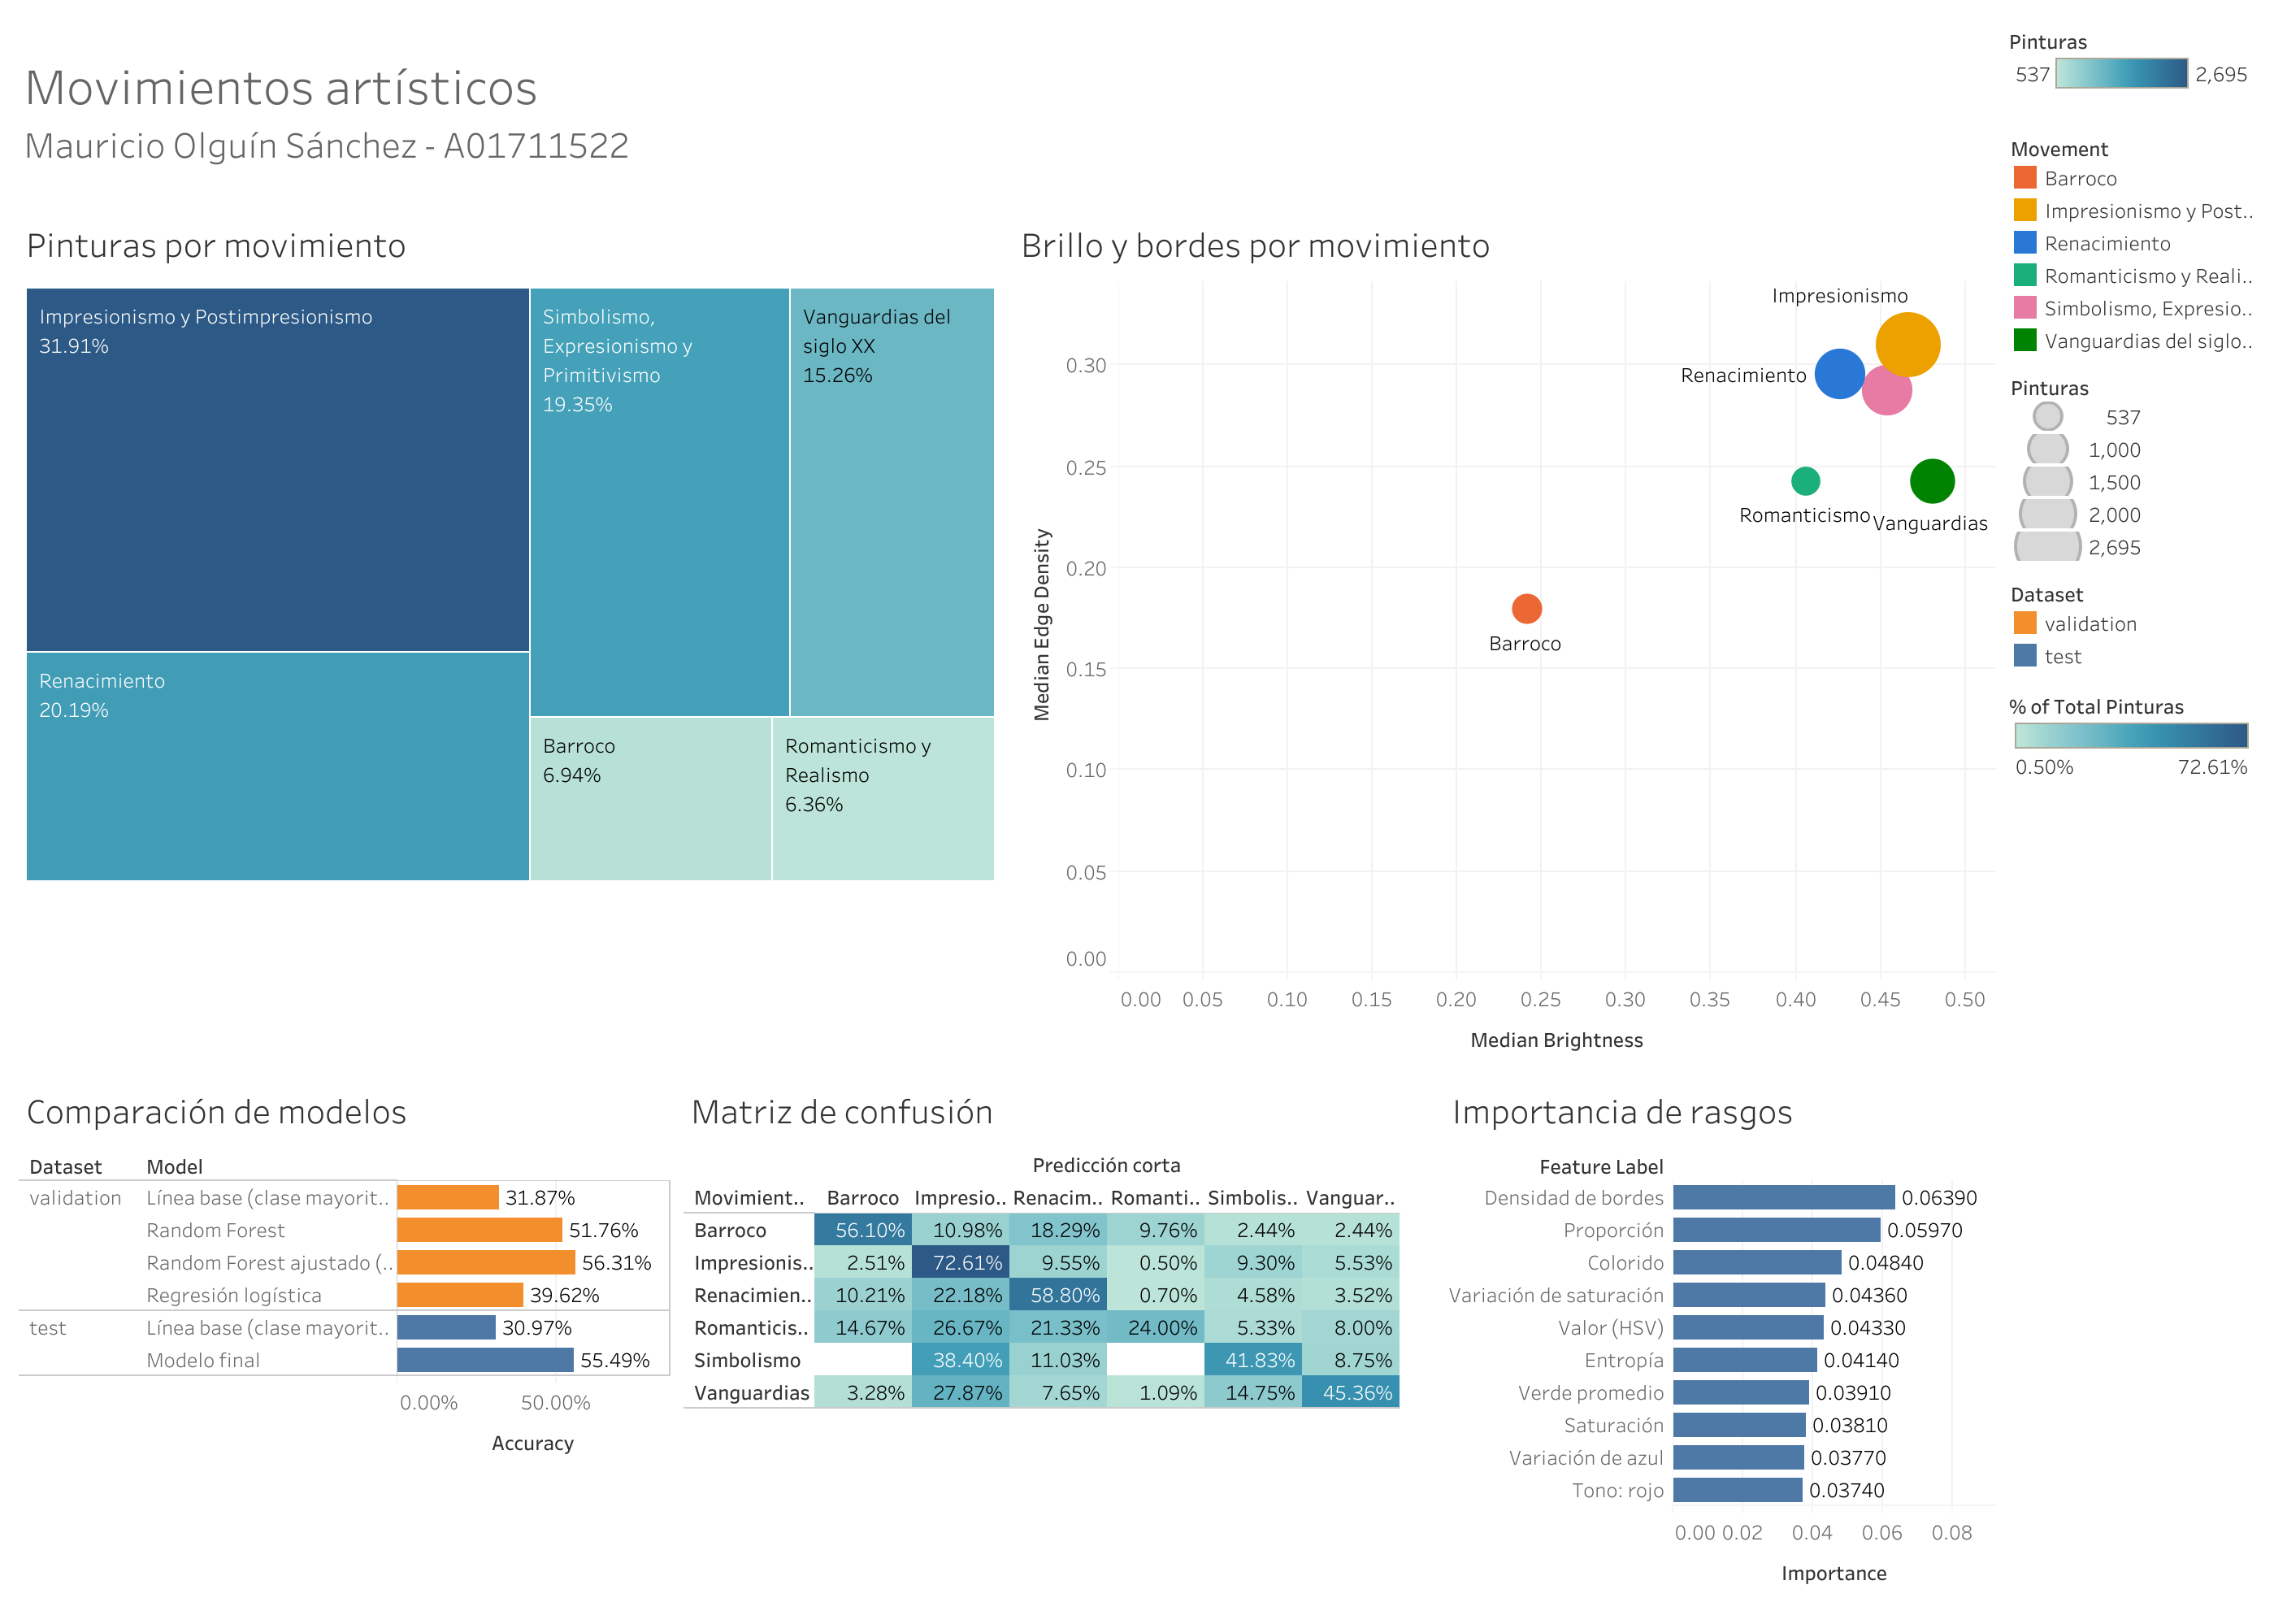

In [27]:
from IPython.display import Image

display(Image(filename="tableau/dashboard_final.png"))


### 8.1 Gráficas del EDA

En la parte de arriba están las dos gráficas del EDA: la distribución de las clases y la mediana de brillo y de densidad de bordes de cada movimiento.

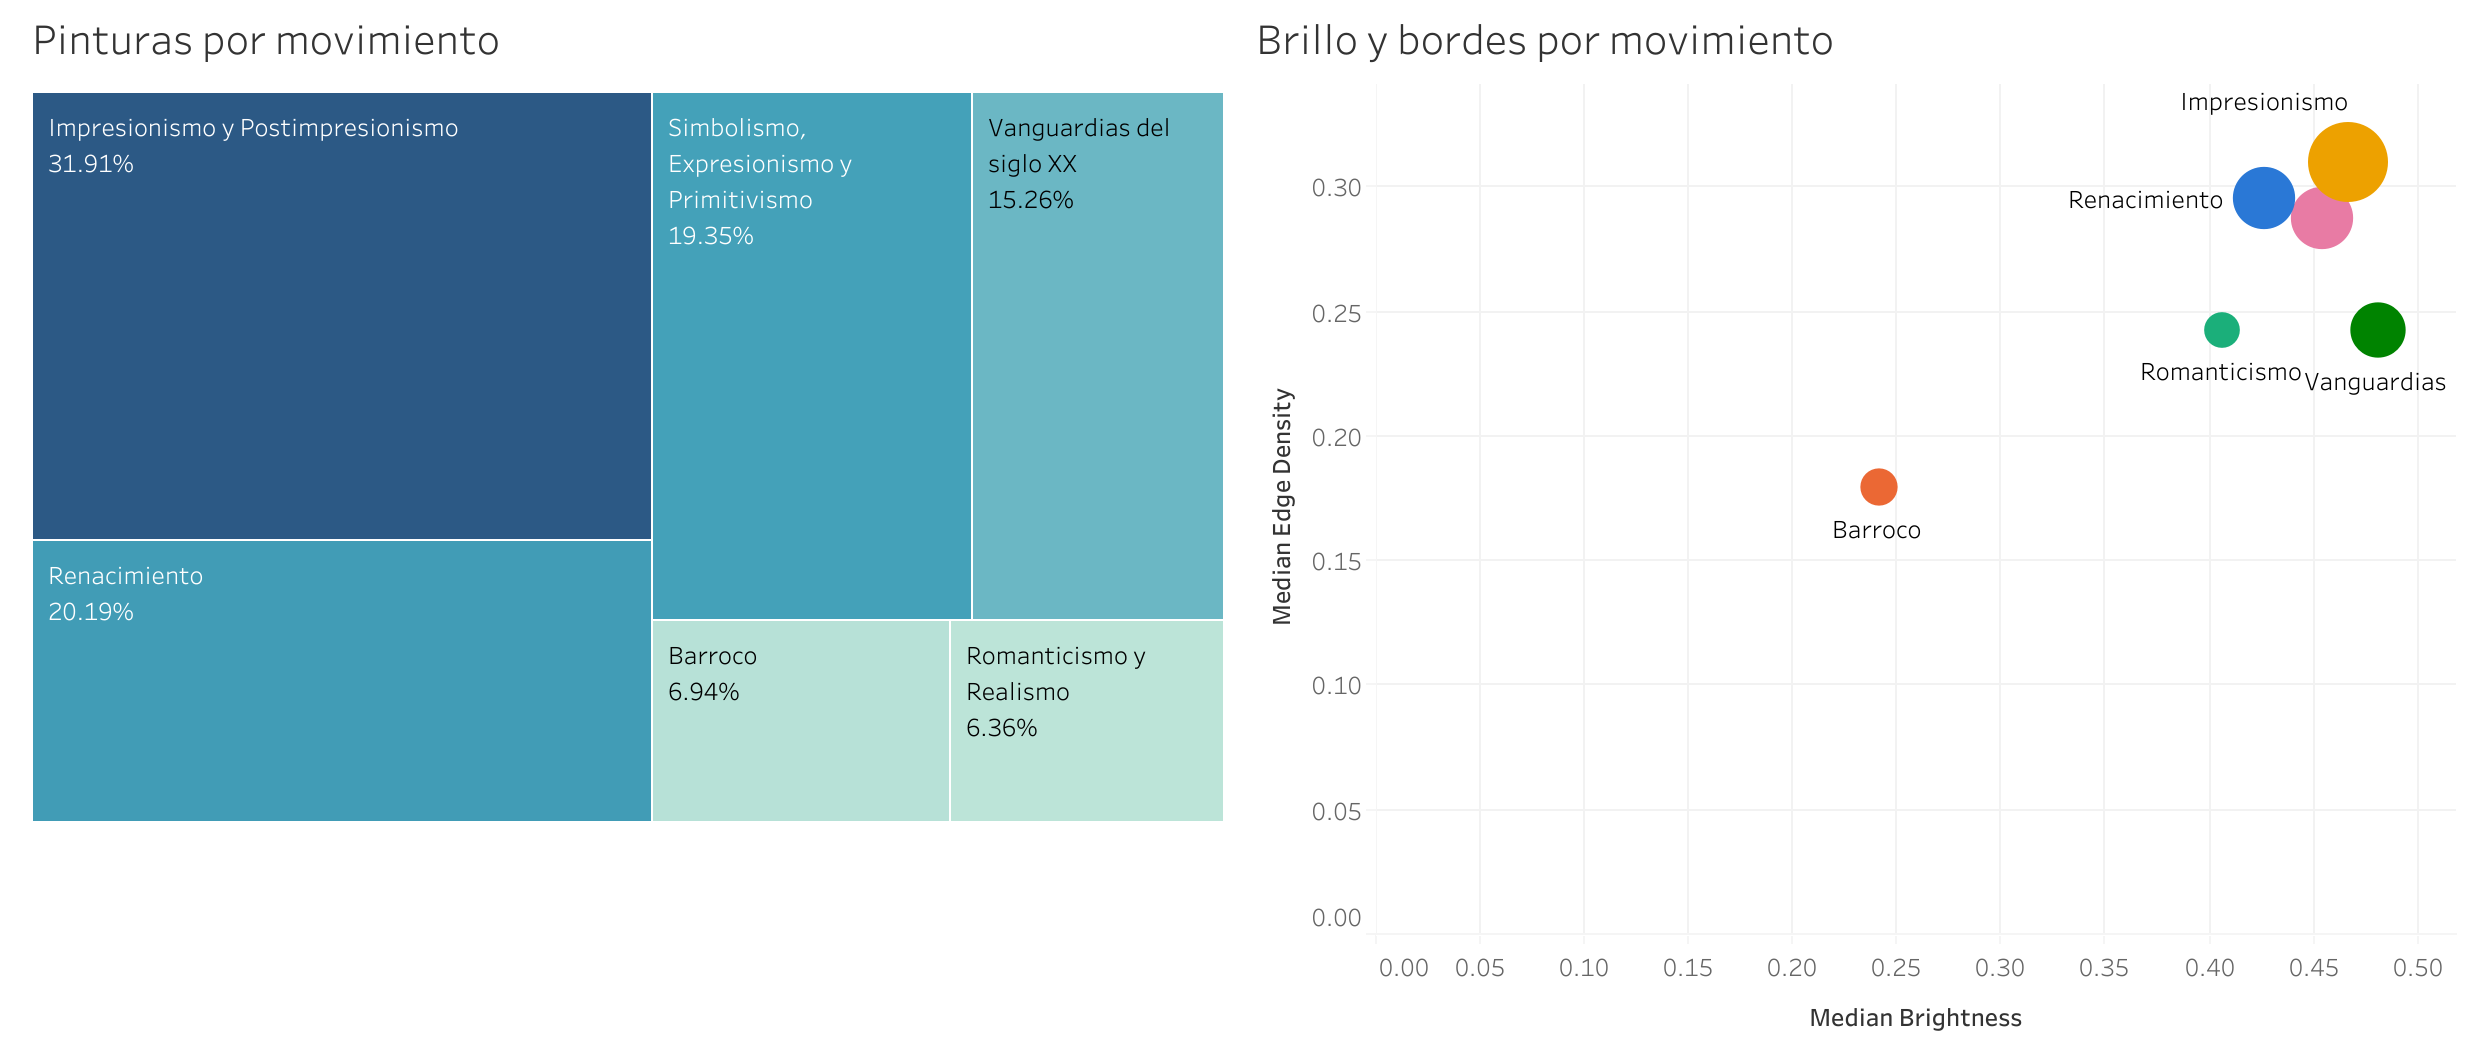

In [28]:
display(Image(filename="tableau/capturas/dashboard_eda.png"))


De lo anterior, se puede observar que:

- Impresionismo y Postimpresionismo concentra el 31.91% de las pinturas, mientras que Barroco (6.94%) y Romanticismo y Realismo (6.36%) son las clases chicas. Por eso utilicé pesos por clase.
- El Barroco queda separado de los demás movimientos, con la menor mediana de brillo (0.24) y de densidad de bordes (0.18).
- Impresionismo tiene la mayor densidad de bordes (0.31), aunque queda cerca de Renacimiento y Simbolismo, por lo que estos dos rasgos no bastan para separarlos.

### 8.2 Gráficas del modelo

En la parte de abajo están las tres gráficas del modelo: la comparación de modelos, la matriz de confusión en `test` (en porcentaje por fila) y los 10 rasgos más importantes. En la comparación, el modelo final es el Random Forest ajustado, reentrenado con `train` y `validation`.

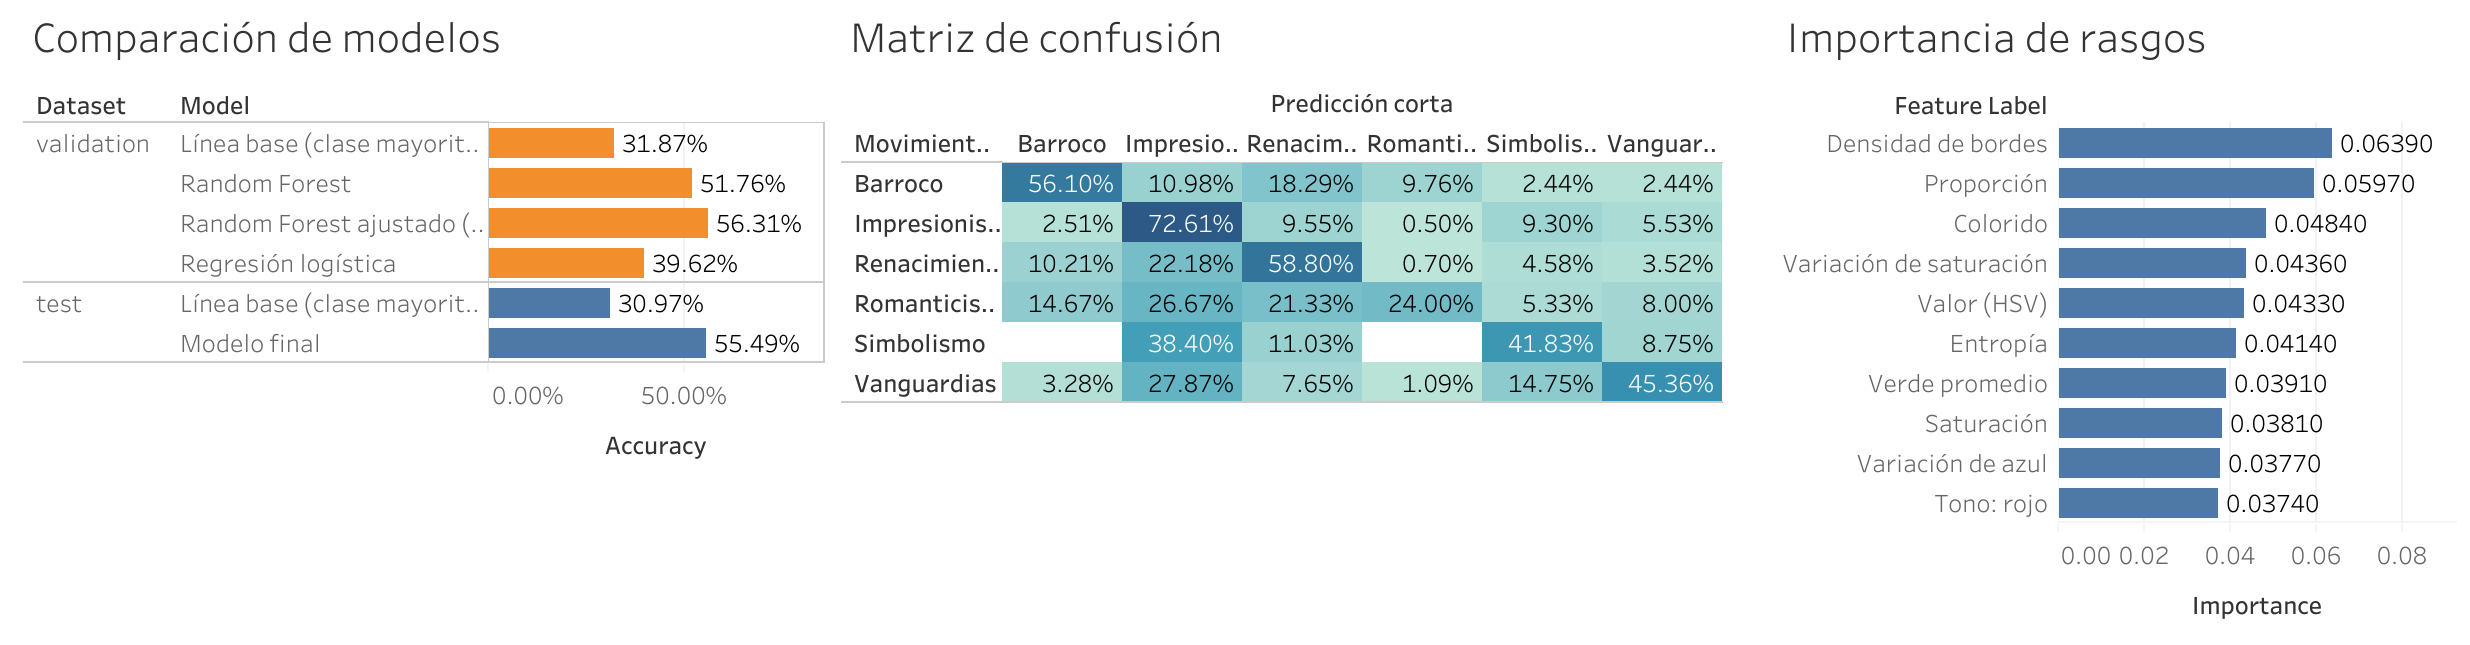

In [29]:
display(Image(filename="tableau/capturas/dashboard_modelo.png"))


De lo anterior, se puede observar que:

- En `validation`, el Random Forest ajustado fue el mejor (56.31%), y en `test` el modelo final acertó el 55.49%, contra 30.97% de la línea base.
- Impresionismo es la clase con el mejor recall (72.61%) y Romanticismo la peor (24.00%).
- La columna de Impresionismo recibe hasta el 38.40% de Simbolismo, por lo que funciona como destino por defecto cuando el modelo duda. Las dos celdas vacías de la fila de Simbolismo son 0%.
- La densidad de bordes (0.0639) y la proporción (0.0597) son los rasgos más importantes. Sin embargo, ninguno domina, ya que los 10 primeros suman cerca del 45%.

Esto coincide con lo que vi en el EDA, ya que la densidad de bordes, que separa al Barroco de Impresionismo, también es el rasgo más útil para el modelo.

## 9. Conclusiones

En esta evidencia construí un flujo completo con PySpark, desde 1.56 GB de imágenes hasta un modelo y un tablero público. Primero, leí las 8,774 imágenes, quité los 328 duplicados de Durero y agrupé los 21 géneros principales en 6 movimientos. Después, describí cada pintura con números de color y textura, y guardé las 8,446 pinturas en un Parquet de unos pocos MB, por lo que todo el análisis se hizo sobre un archivo mucho más ligero.

El EDA confirmó un desbalance fuerte entre las clases y diferencias claras de brillo, textura, proporción y colorido entre movimientos. Esto me sirvió para tomar decisiones concretas, como darles más peso a las clases chicas y no utilizar el tamaño de las imágenes.

Para el modelo, separé los datos en tres conjuntos, para poder elegir el mejor modelo sin tocar las pinturas de prueba. El Random Forest superó a la regresión logística y, ya ajustado, acertó el 55.5% de las pinturas de prueba, contra 31.0% de la línea base. Funciona mejor en Impresionismo y Renacimiento y peor en Romanticismo y Realismo.

Aun sin saber qué representa la pintura, el color y la textura bastan para acertar el movimiento en más de la mitad de los casos, es decir, 1.8 veces la línea base. Además, los rasgos más útiles (bordes, proporción y colorido) tienen una lectura artística clara, como la pincelada visible del Impresionismo, el claroscuro del Barroco o la paleta más viva de las vanguardias. Sin embargo, no quiero decir que el modelo entienda de arte: con pintores nuevos sólo acertó 1 de 8, aunque en las 8 el movimiento correcto quedó entre sus tres opciones más probables. Esto me indica que buena parte de lo aprendido es el estilo de los 50 artistas del dataset.

In [28]:
spark.stop()

# Link al repositorio en github

https://github.com/EmilioQuinonez/VACAS_IA/tree/main/docs/RETO_DATOS/proyecto_individual